# GuardianTransit — Face Recognition Pipeline

## Design Principles: Unified Canonical Gallery

To address the architectural inconsistencies with multiple gallery structures, we are implementing a single source of truth for all enrolled students. This canonical gallery, named `student_profiles`, will hold all per-image embeddings for each student.

### Key Principles:

1.  **One Canonical Gallery**: All recognition, validation, and enrollment processes will refer to `student_profiles` as the definitive list of enrolled students and their embeddings.

2.  **Explicit Staging & Promotion**: New student enrollments will first create a temporary *staging profile*. This staging profile will undergo validation (e.g., duplicate checks against the canonical gallery) before being explicitly *promoted* to the `student_profiles`.

3.  **No Direct Modification of Canonical Gallery During Staging**: The canonical `student_profiles` will only be modified during the explicit promotion step.

4.  **Dynamic Derived Galleries (If Needed)**: Any derived galleries (e.g., mean embeddings for faster lookups) will be generated on-the-fly from the `student_profiles` when needed for a specific function, rather than being persistently stored as global variables.

### High-Level Flow:

*   **Initialization**: `student_profiles` is initially populated with any existing verified students.
*   **New Enrollment**:
    1.  `stage_new_student_enrollment(student_id, image_dir, canonical_student_profiles)`: Processes images for a new student, generates embeddings, performs duplicate checks against `canonical_student_profiles`, and returns a *staging profile* (or an error).
    2.  `promote_student_to_canonical_gallery(staging_result, canonical_student_profiles)`: Takes a successful `staging_result` and merges it into `canonical_student_profiles`.
*   **Recognition/Validation**: All functions (`recognize_enrolled_students`, `recognize_leave_one_out`, comparison functions) directly use `student_profiles`.

This approach ensures consistency, prevents stale data, and clarifies the data flow for student management and recognition.

## 0. Configuration & Paths

In [140]:
import os
import sys
from pathlib import Path

# Clone the main repository if not already present
%cd /content
!git clone --branch ai-pipeline-development https://github.com/eng-yash007/Gurdian_transit.git
%cd /content/Gurdian_transit

PROJECT_ROOT = Path("/content/Gurdian_transit")
DATA = Path("/content/drive/MyDrive/data")
CROP_DIR = Path("/content/face_crops")
MODEL_PATH = "/content/yolov8-face/yolov8m-face-lindevs.pt"

# Ensure the ai_pipeline is in the system path for imports
ai_path = PROJECT_ROOT / "ai_pipeline"
if str(ai_path) not in sys.path:
    sys.path.insert(0, str(ai_path))

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA}")
print(f"Face crops directory: {CROP_DIR}")
print(f"YOLOv8-face model path: {MODEL_PATH}")

/content
fatal: destination path 'Gurdian_transit' already exists and is not an empty directory.
/content/Gurdian_transit
Project root: /content/Gurdian_transit
Data directory: /content/drive/MyDrive/data
Face crops directory: /content/face_crops
YOLOv8-face model path: /content/yolov8-face/yolov8m-face-lindevs.pt


## 1. Environment / GPU Check

In [141]:
import torch
import ultralytics
import insightface
import onnxruntime as ort

# Check GPU
!nvidia-smi

print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Install/check required packages
%cd {PROJECT_ROOT}
!pip install -r ai_pipeline/requirements.txt

# Reinstall opencv-python-headless for CascadeClassifier support (if needed, this was an issue in history)
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
!pip install --no-cache-dir opencv-python-headless==4.10.0.84

import cv2
print("\nOpenCV version:", cv2.__version__)
print("Has CascadeClassifier (expected False with headless):", hasattr(cv2, "CascadeClassifier"))

# Install ultralytics
!pip install -q -U ultralytics
print("\nUltralytics version:", ultralytics.__version__)

# InsightFace/ONNXRuntime check
print("\nInsightFace:", insightface.__version__)
print("ONNX providers:", ort.get_available_providers())

# Create __init__.py if it doesn't exist for local package imports
init_file = PROJECT_ROOT / "ai_pipeline" / "video_verification" / "__init__.py"
if not init_file.exists():
    init_file.touch()
    print(f"Created: {init_file.name}")

# Run pytest to verify setup (optional, but in history)
# !PYTHONPATH={PROJECT_ROOT}/ai_pipeline pytest ai_pipeline/video_verification/tests -q

Tue Sep 22 08:37:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   78C    P0             33W /   70W |    1123MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----


OpenCV version: 5.0.0
Has CascadeClassifier (expected False with headless): False
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
insightface 2.0 requires onnxruntime, which is not installed.

Ultralytics version: 8.4.158

InsightFace: 2.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 2. Dataset Inspection

In [142]:
import pandas as pd
from PIL import Image

print("Dataset exists:", DATA.exists())

records = []

for student_dir in sorted(DATA.iterdir()):
    if student_dir.is_dir():
        images = [
            p for p in student_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]

        print(f"\n===== {student_dir.name} =====")
        for image_path in sorted(images):
            try:
                with Image.open(image_path) as img:
                    width, height = img.size
                    mode = img.mode
                    print(f"{image_path.name:35} {width}x{height} {mode}")
                    records.append({
                        "student": student_dir.name,
                        "image_name": image_path.name,
                        "width": width,
                        "height": height,
                        "mode": mode,
                        "path": str(image_path)
                    })
            except Exception as e:
                print(f"{image_path.name}: ERROR -> {e}")

df_dataset_info = pd.DataFrame(records)
print("\nDataset Info DataFrame:")
display(df_dataset_info)

Dataset exists: True

===== stud001 =====
WhatsApp Image 2026-09-21 at 18.55.22.jpeg 1316x1599 RGB
WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg 1504x1599 RGB
WhatsApp Image 2026-09-21 at 18.55.23.jpeg 1258x1599 RGB

===== stud002 =====
img1.jpeg                           1000x1600 RGB
img2.jpeg                           1000x1600 RGB
img3.jpeg                           1000x1600 RGB
img4.jpeg                           1000x1600 RGB
img6.jpeg                           1000x1600 RGB
img7.jpeg                           1000x1600 RGB
img8.jpeg                           1000x1600 RGB
ing5.jpeg                           1000x1600 RGB

===== stud003 =====
WhatsApp Image 2026-09-21 at 22.47.25.jpeg 1201x1600 RGB
img2.jpeg                           1201x1600 RGB
img3.jpeg                           1201x1600 RGB
img4.jpeg                           1201x1600 RGB
img5.jpeg                           1201x1600 RGB
img6.jpeg                           1201x1600 RGB
img7.jpeg                         

,student,image_name,width,height,mode,path
0,stud001,WhatsApp Image 2026-09-21 at 18.55.22.jpeg,1316,1599,RGB,/content/drive/MyDrive/data/stud001/WhatsApp I...
1,stud001,WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg,1504,1599,RGB,/content/drive/MyDrive/data/stud001/WhatsApp I...
2,stud001,WhatsApp Image 2026-09-21 at 18.55.23.jpeg,1258,1599,RGB,/content/drive/MyDrive/data/stud001/WhatsApp I...
3,stud002,img1.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img1.jpeg
4,stud002,img2.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img2.jpeg
5,stud002,img3.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img3.jpeg
6,stud002,img4.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img4.jpeg
7,stud002,img6.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img6.jpeg
8,stud002,img7.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img7.jpeg
9,stud002,img8.jpeg,1000,1600,RGB,/content/drive/MyDrive/data/stud002/img8.jpeg


## 3. YOLO Face Detector

In [150]:
from ultralytics import YOLO

# Clone yolov8-face if not present and download model
%cd /content
!git clone https://github.com/lindevs/yolov8-face.git
%cd /content/yolov8-face

!wget -O yolov8m-face-lindevs.pt https://github.com/lindevs/yolov8-face/releases/latest/download/yolov8m-face-lindevs.pt

# Load YOLO model
model = YOLO(MODEL_PATH)
print("YOLOv8-face model loaded successfully!")

# Perform initial detection and summarize (from previous history)
detection_records = []

for _, row in df_dataset_info.iterrows():
    image_path = Path(row['path'])

    results = model.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    result = results[0]
    face_count = len(result.boxes)

    best_conf = 0
    largest_face_area = 0

    if face_count > 0:
        confidences = result.boxes.conf.cpu().numpy()
        best_conf = float(max(confidences))

        boxes = result.boxes.xyxy.cpu().numpy()
        areas = []
        for box in boxes:
            x1, y1, x2, y2 = box
            area = max(0, x2 - x1) * max(0, y2 - y1)
            areas.append(area)
        largest_face_area = max(areas)

    detection_records.append({
        "student": row['student'],
        "image": row['image_name'],
        "faces_detected": face_count,
        "best_confidence": round(best_conf, 4),
        "largest_face_area": round(largest_face_area, 0)
    })

df_detection_summary = pd.DataFrame(detection_records)

print("\n--- YOLO Detection Summary ---")
display(df_detection_summary)
print("\nTotal images:", len(df_detection_summary))
print("Images with faces:", (df_detection_summary["faces_detected"] > 0).sum())
print("Images with no face:", (df_detection_summary["faces_detected"] == 0).sum())

display(df_detection_summary.groupby("student").agg(
    images=("image", "count"),
    successful=("faces_detected", lambda x: (x > 0).sum()),
    avg_confidence=("best_confidence", "mean"),
    min_confidence=("best_confidence", "min")
))

/content
fatal: destination path 'yolov8-face' already exists and is not an empty directory.
/content/yolov8-face
--2026-09-22 08:39:44--  https://github.com/lindevs/yolov8-face/releases/latest/download/yolov8m-face-lindevs.pt
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/lindevs/yolov8-face/releases/download/1.0.1/yolov8m-face-lindevs.pt [following]
--2026-09-22 08:39:45--  https://github.com/lindevs/yolov8-face/releases/download/1.0.1/yolov8m-face-lindevs.pt
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/726537896/08baafb9-aeea-4c8c-a360-24f7adba16bd?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-09-22T09%3A25%3A01Z&rscd=attachment%3B+filename%3Dyolov8m-face-lindevs.pt&rsct=application%2Foctet-stream&sko

,student,image,faces_detected,best_confidence,largest_face_area
0,stud001,WhatsApp Image 2026-09-21 at 18.55.22.jpeg,1,0.8760,167991.0
1,stud001,WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg,1,0.9182,162032.0
2,stud001,WhatsApp Image 2026-09-21 at 18.55.23.jpeg,1,0.8746,156503.0
3,stud002,img1.jpeg,1,0.9000,306771.0
4,stud002,img2.jpeg,1,0.8883,282087.0
5,stud002,img3.jpeg,1,0.8738,272415.0
6,stud002,img4.jpeg,1,0.8842,298749.0
7,stud002,img6.jpeg,1,0.8659,175600.0
8,stud002,img7.jpeg,1,0.8752,282923.0
9,stud002,img8.jpeg,1,0.9036,330998.0



Total images: 19
Images with faces: 19
Images with no face: 0


,images,successful,avg_confidence,min_confidence
student,,,,
stud001,3,3,0.889600,0.8746
stud002,8,8,0.883587,0.8659
stud003,8,8,0.885325,0.8751


## 4. Face Crop Generation

✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.22.jpeg → 431x658
✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg → 462x593
✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.23.jpeg → 423x625
✅ stud002 | img1.jpeg → 655x792
✅ stud002 | img2.jpeg → 624x764
✅ stud002 | img3.jpeg → 577x763
✅ stud002 | img4.jpeg → 682x741
✅ stud002 | img6.jpeg → 510x581
✅ stud002 | img7.jpeg → 590x810
✅ stud002 | img8.jpeg → 683x819
✅ stud002 | ing5.jpeg → 599x696
✅ stud003 | WhatsApp Image 2026-09-21 at 22.47.25.jpeg → 433x634
✅ stud003 | img2.jpeg → 483x722
✅ stud003 | img3.jpeg → 430x603
✅ stud003 | img4.jpeg → 426x606
✅ stud003 | img5.jpeg → 453x631
✅ stud003 | img6.jpeg → 458x655
✅ stud003 | img7.jpeg → 460x637
✅ stud003 | img8.jpeg → 476x672

Total crops generated: 19


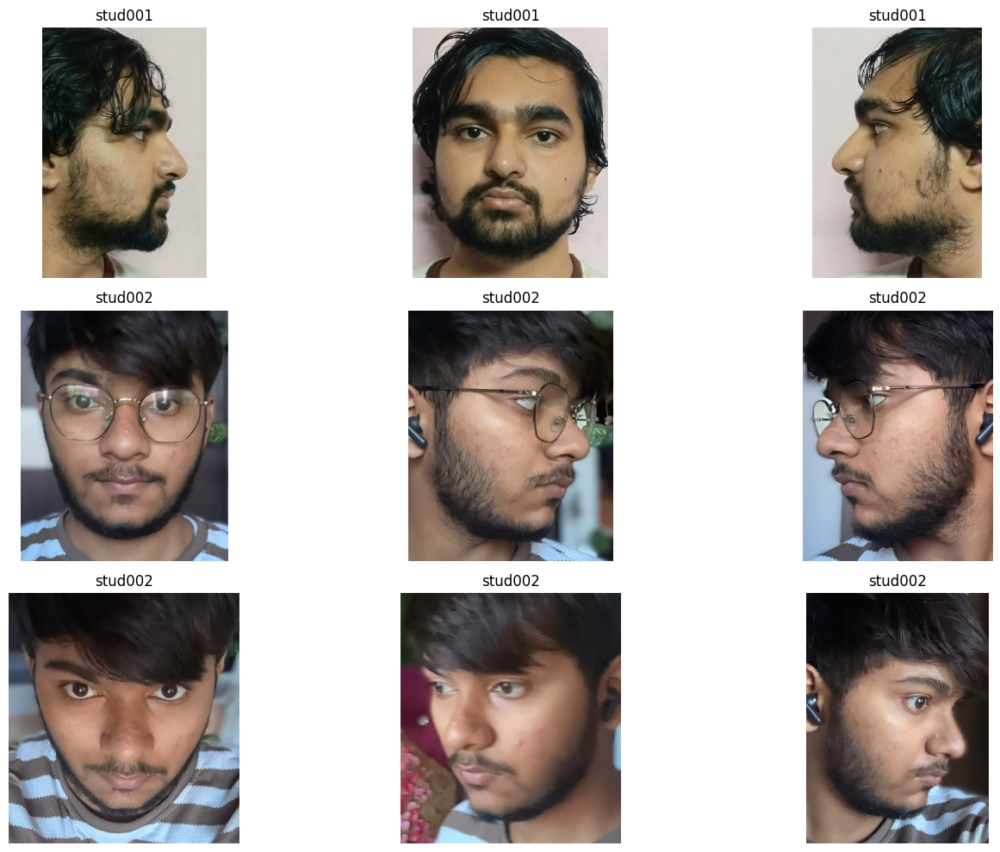

In [152]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

CROP_DIR.mkdir(parents=True, exist_ok=True)
PADDING = 0.15

crop_records = []

for _, row in df_dataset_info.iterrows():
    student_id = row['student']
    image_path = Path(row['path'])

    student_crop_dir = CROP_DIR / student_id
    student_crop_dir.mkdir(parents=True, exist_ok=True)

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"❌ Could not read: {image_path}")
        continue

    h, w = image.shape[:2]

    results = model.predict(
        source=str(image_path),
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )

    result = results[0]

    if len(result.boxes) == 0:
        print(f"❌ No face: {image_path.name}")
        continue

    # Select largest face
    boxes = result.boxes.xyxy.cpu().numpy()

    best_box = None
    best_area = 0

    for box in boxes:
        x1, y1, x2, y2 = box
        area = max(0, x2 - x1) * max(0, y2 - y1)
        if area > best_area:
            best_area = area
            best_box = box

    x1, y1, x2, y2 = best_box

    face_w = x2 - x1
    face_h = y2 - y1

    # 15% padding
    pad_x = face_w * PADDING
    pad_y = face_h * PADDING

    x1 = max(0, int(x1 - pad_x))
    y1 = max(0, int(y1 - pad_y))
    x2 = min(w, int(x2 + pad_x))
    y2 = min(h, int(y2 + pad_y))

    # Crop
    face_crop = image[y1:y2, x1:x2]

    # Save
    output_name = image_path.stem + "_face.jpg"
    output_path = student_crop_dir / output_name

    cv2.imwrite(str(output_path), face_crop)

    crop_records.append({
        "student": student_id,
        "original": image_path.name,
        "crop_path": str(output_path),
        "width": face_crop.shape[1],
        "height": face_crop.shape[0]
    })

    print(
        f"✅ {student_id} | "
        f"{image_path.name} → "
        f"{face_crop.shape[1]}x{face_crop.shape[0]}"
    )

df_crops = pd.DataFrame(crop_records)
print("\nTotal crops generated:", len(df_crops))

# Display some generated face crops
crop_paths_for_display = sorted(CROP_DIR.rglob("*.jpg"))

plt.figure(figsize=(15, 10))
for i, path in enumerate(crop_paths_for_display[:9]):
    img_display = cv2.imread(str(path))
    img_display = cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB)
    plt.subplot(3, 3, i + 1)
    plt.imshow(img_display)
    plt.title(path.parent.name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. InsightFace Setup

In [145]:
from insightface.app import FaceAnalysis

app = FaceAnalysis(
    name="buffalo_l",
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)

app.prepare(
    ctx_id=0,
    det_size=(640, 640)
)

recognition_model = app.models["recognition"]
landmark_model = app.models["landmark_2d_106"]

print("InsightFace loaded successfully!")
print("Recognition model input size:", recognition_model.input_size)
print("Landmark model has", landmark_model.lmk_num, "landmarks.")

InsightFace loaded successfully!
Recognition model input size: (112, 112)
Landmark model has 106 landmarks.


## 6. 106-Point Landmark Detection

Landmarks shape: (106, 2)
First 5 landmarks:
 [[     306.74      541.68]
 [     68.175      270.84]
 [      126.1      499.91]
 [     148.12       516.4]
 [     172.65      529.78]]


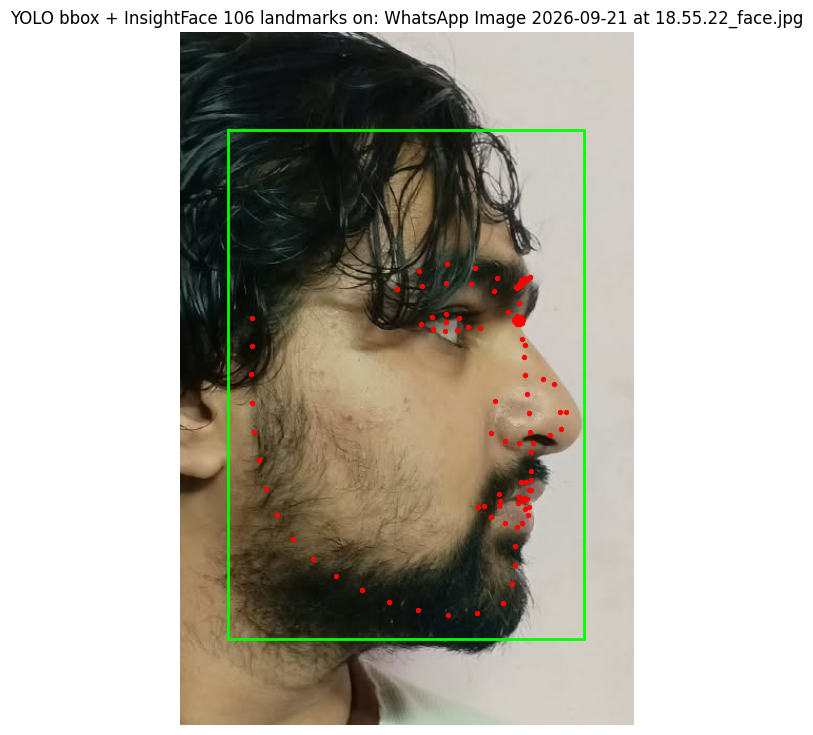

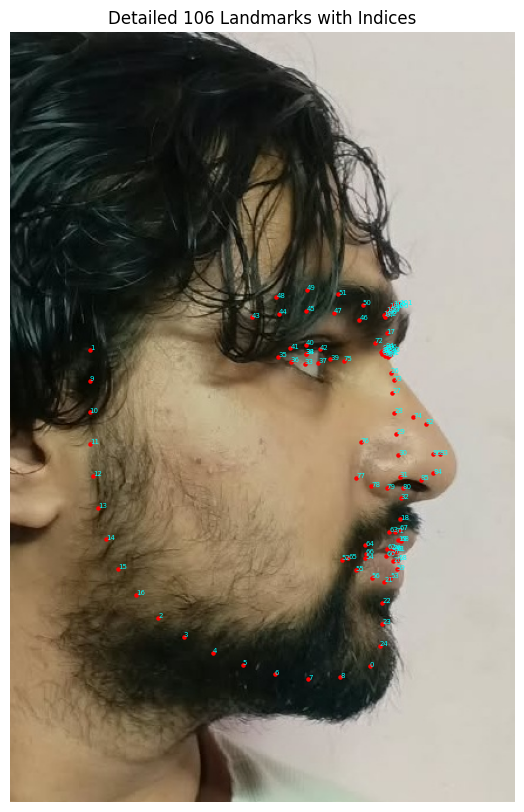

In [146]:
from insightface.app.common import Face

# Pick one generated face crop for demonstration
demo_crop_path = Path(df_crops['crop_path'].iloc[0])

demo_image = cv2.imread(str(demo_crop_path))
h, w, _ = demo_image.shape

# Run YOLO detection on the crop to get a precise bounding box within the crop
yolo_results = model.predict(
    demo_image,
    conf=0.25,
    verbose=False
)
boxes = yolo_results[0].boxes.xyxy.cpu().numpy()

if len(boxes) == 0:
    print("No face detected in the demo crop by YOLO.")
else:
    # Use the first detected box within the crop
    bbox_in_crop = boxes[0].astype(np.float32)

    # Create a Face object for InsightFace
    face = Face(bbox=bbox_in_crop)

    # Get 106 landmarks
    landmarks = landmark_model.get(demo_image, face)

    print("Landmarks shape:", landmarks.shape)
    print("First 5 landmarks:\n", landmarks[:5])

    # Visualize
    img_rgb = cv2.cvtColor(demo_image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(7, 9))
    plt.imshow(img_rgb)
    plt.scatter(
        landmarks[:, 0],
        landmarks[:, 1],
        s=8,
        color='red'
    )

    # Draw YOLO bbox on the crop
    x1, y1, x2, y2 = bbox_in_crop
    plt.plot(
        [x1, x2, x2, x1, x1],
        [y1, y1, y2, y2, y1],
        linewidth=2,
        color='lime'
    )

    plt.axis("off")
    plt.title(f"YOLO bbox + InsightFace 106 landmarks on: {demo_crop_path.name}")
    plt.show()

    # Detailed visualization with landmark indices
    plt.figure(figsize=(8, 10))
    plt.imshow(cv2.cvtColor(demo_image, cv2.COLOR_BGR2RGB))
    for i, (x, y) in enumerate(landmarks):
        plt.scatter(x, y, s=5, color='red')
        plt.text(x, y, str(i), fontsize=5, color='cyan')
    plt.axis("off")
    plt.title("Detailed 106 Landmarks with Indices")
    plt.show()

## 7. 5-Point Alignment

5 ArcFace alignment landmarks:
 [[     252.31      274.54]
 [     318.91      272.72]
 [     360.87      360.44]
 [     282.82      450.34]
 [     329.57      442.72]]


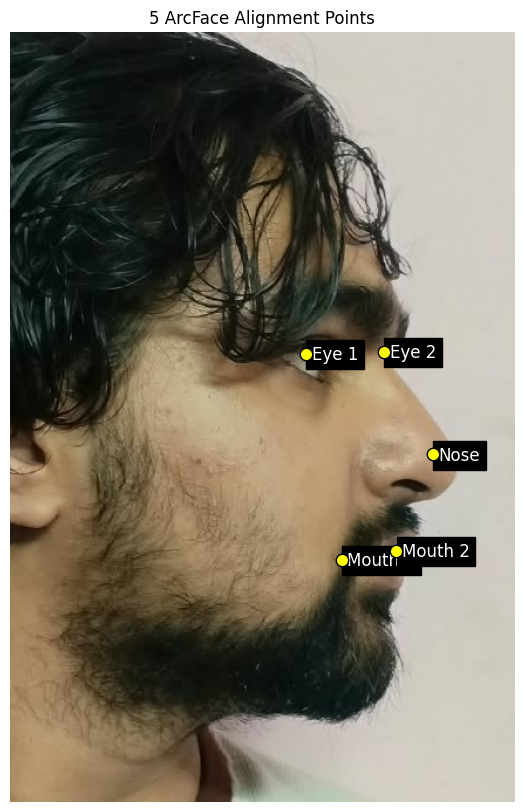

Aligned face shape: (112, 112, 3)


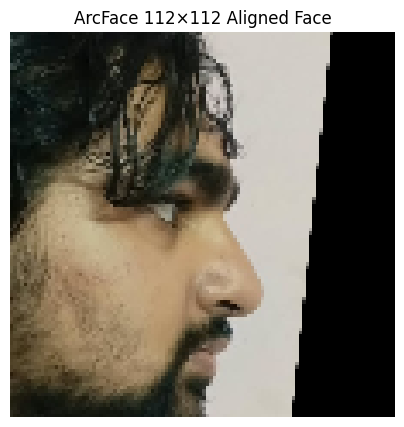

In [147]:
from insightface.utils import face_align

# Select 5 specific landmarks for ArcFace alignment (eyes, nose, mouth corners)
five_points = np.array([
    landmarks[38],   # eye 1 (left eye inner corner)
    landmarks[88],   # eye 2 (right eye inner corner)
    landmarks[86],   # nose (tip)
    landmarks[52],   # mouth corner 1 (left)
    landmarks[61],   # mouth corner 2 (right)
], dtype=np.float32)

print("5 ArcFace alignment landmarks:\n", five_points)

# Visualize the 5 points
img_rgb = cv2.cvtColor(demo_image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 10))
plt.imshow(img_rgb)

labels = [
    "Eye 1",
    "Eye 2",
    "Nose",
    "Mouth 1",
    "Mouth 2"
]

for point, label in zip(five_points, labels):
    x, y = point
    plt.scatter(x, y, s=80, color='yellow', edgecolor='black', zorder=5)
    plt.text(x + 5, y + 5, label, fontsize=12, color='white', backgroundcolor='black')

plt.axis("off")
plt.title("5 ArcFace Alignment Points")
plt.show()

# Perform ArcFace alignment
aligned_face = face_align.norm_crop(
    demo_image,
    landmark=five_points,
    image_size=112
)

print("Aligned face shape:", aligned_face.shape)

aligned_rgb = cv2.cvtColor(aligned_face, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(5, 5))
plt.imshow(aligned_rgb)
plt.axis("off")
plt.title("ArcFace 112×112 Aligned Face")
plt.show()

## 8. ArcFace Embedding Generation

In [148]:
def get_aligned_embedding(image):
    """
    YOLO → 106 landmarks → 5 points → ArcFace alignment → embedding
    """
    # 1. YOLO face detection
    results = model.predict(
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()
    if len(boxes) == 0:
        return None

    # Highest-confidence face
    confidences = results[0].boxes.conf.cpu().numpy()
    best_idx = np.argmax(confidences)
    bbox = boxes[best_idx].astype(np.float32)

    # 2. 106 landmarks
    face = Face(bbox=bbox)
    landmarks = landmark_model.get(image, face)

    # 3. Five alignment points
    five_points = np.array([
        landmarks[38],
        landmarks[88],
        landmarks[86],
        landmarks[52],
        landmarks[61]
    ], dtype=np.float32)

    # 4. ArcFace alignment
    aligned = face_align.norm_crop(
        image,
        landmark=five_points,
        image_size=112
    )

    # 5. ArcFace embedding
    embedding = recognition_model.get_feat(aligned)[0]

    # L2 normalize
    embedding = embedding / (
        np.linalg.norm(embedding) + 1e-12
    )

    return embedding


print("Testing get_aligned_embedding function...")
demo_embedding = get_aligned_embedding(demo_image)

if demo_embedding is not None:
    print("Embedding shape:", demo_embedding.shape)
    print("Embedding norm:", np.linalg.norm(demo_embedding))
    print("First 10 values:", demo_embedding[:10])
else:
    print("Failed to generate embedding for demo image.")


# Generate embeddings for all cropped faces
embeddings = {}
failed_embeddings = []

for _, row in df_crops.iterrows():
    student_id = row['student']
    crop_path = Path(row['crop_path'])

    image = cv2.imread(str(crop_path))
    if image is None:
        failed_embeddings.append((student_id, crop_path.name, "image_read_failed"))
        continue

    emb = get_aligned_embedding(image)

    if emb is None:
        failed_embeddings.append((student_id, crop_path.name, "no_face_detected_or_alignment_failed"))
        continue

    embeddings.setdefault(student_id, {})[crop_path.name] = emb
    print(f"✓ {student_id}/{crop_path.name}")

print("\n--- Embedding Generation Summary ---")
for student_id, imgs in embeddings.items():
    print(student_id, "→", len(imgs), "embeddings")

print("Failed to generate embeddings for:", len(failed_embeddings))
if failed_embeddings:
    for f in failed_embeddings:
        print(f)

Testing get_aligned_embedding function...
Embedding shape: (512,)
Embedding norm: 0.99999994
First 10 values: [   0.039364     0.13324   -0.037517    -0.02941   -0.019254    0.079645     0.02952     0.05144    0.076519  -0.0037799]
✓ stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg
✓ stud001/WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg
✓ stud001/WhatsApp Image 2026-09-21 at 18.55.23_face.jpg
✓ stud002/img1_face.jpg
✓ stud002/img2_face.jpg
✓ stud002/img3_face.jpg
✓ stud002/img4_face.jpg
✓ stud002/img6_face.jpg
✓ stud002/img7_face.jpg
✓ stud002/img8_face.jpg
✓ stud002/ing5_face.jpg
✓ stud003/WhatsApp Image 2026-09-21 at 22.47.25_face.jpg
✓ stud003/img2_face.jpg
✓ stud003/img3_face.jpg
✓ stud003/img4_face.jpg
✓ stud003/img5_face.jpg
✓ stud003/img6_face.jpg
✓ stud003/img7_face.jpg
✓ stud003/img8_face.jpg

--- Embedding Generation Summary ---
stud001 → 3 embeddings
stud002 → 8 embeddings
stud003 → 8 embeddings
Failed to generate embeddings for: 0


## 9. Offline Recognition Evaluation

Total embeddings for comparison: 19

Total comparisons: 171

Same person vs. Different person counts:


,count
same_person,
False,112
True,59



SAME PERSON SIMILARITIES
Count : 59
Min   : 0.5155221223831177
Mean  : 0.703368207155648
Median: 0.6943768262863159
Max   : 0.9441453218460083
Std   : 0.09383070531838077

DIFFERENT PERSON SIMILARITIES
Count : 112
Min   : 0.0034105107188224792
Mean  : 0.14804259288523877
Median: 0.150835283100605
Max   : 0.25447311997413635
Std   : 0.04336063438036383

TOP DIFFERENT-PERSON MATCHES
--------------------------------
student_1                                            image_1 student_2       image_2  similarity  same_person
  stud001     WhatsApp Image 2026-09-21 at 18.55.23_face.jpg   stud003 img7_face.jpg    0.254473        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.23_face.jpg   stud003 img3_face.jpg    0.247864        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.22_face.jpg   stud003 img7_face.jpg    0.232713        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.22_face.jpg   stud003 img4_face.jpg    0.215276        False
  stud001 WhatsApp Image 2026-09

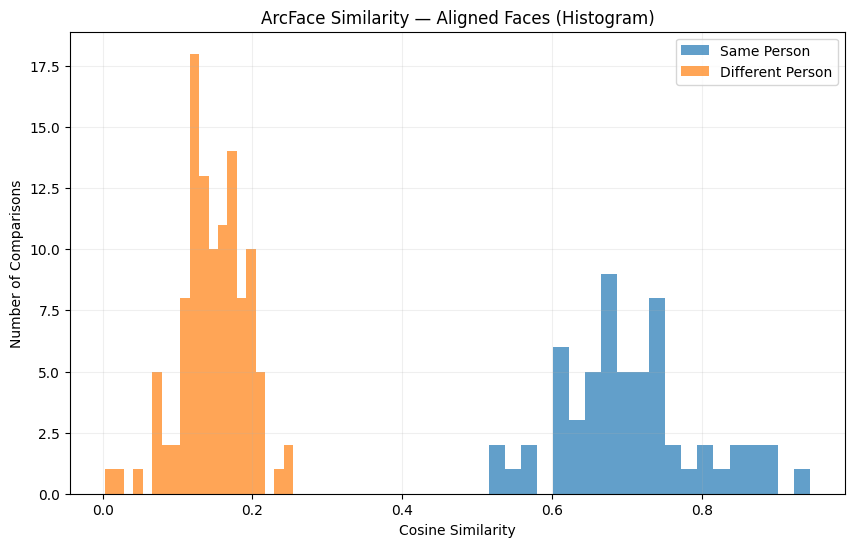


--- Threshold Evaluation Results ---
 threshold  TP  TN  FP  FN      FAR      FRR  accuracy
      0.00  59   0 112   0 1.000000 0.000000  0.345029
      0.01  59   1 111   0 0.991071 0.000000  0.350877
      0.02  59   1 111   0 0.991071 0.000000  0.350877
      0.03  59   2 110   0 0.982143 0.000000  0.356725
      0.04  59   2 110   0 0.982143 0.000000  0.356725
      0.05  59   3 109   0 0.973214 0.000000  0.362573
      0.06  59   3 109   0 0.973214 0.000000  0.362573
      0.07  59   4 108   0 0.964286 0.000000  0.368421
      0.08  59   8 104   0 0.928571 0.000000  0.391813
      0.09  59  10 102   0 0.910714 0.000000  0.403509
      0.10  59  11 101   0 0.901786 0.000000  0.409357
      0.11  59  17  95   0 0.848214 0.000000  0.444444
      0.12  59  28  84   0 0.750000 0.000000  0.508772
      0.13  59  39  73   0 0.651786 0.000000  0.573099
      0.14  59  48  64   0 0.571429 0.000000  0.625731
      0.15  59  55  57   0 0.508929 0.000000  0.666667
      0.16  59  68  44   0 

In [149]:
from itertools import combinations

# Create a flat list of samples for pairwise comparison
samples = []
for student_id, image_dict in embeddings.items():
    for filename, embedding in image_dict.items():
        samples.append({
            "student_id": student_id,
            "filename": filename,
            "embedding": embedding
        })
print("Total embeddings for comparison:", len(samples))

# Perform pairwise comparisons
results = []
for a, b in combinations(samples, 2):
    emb1 = a["embedding"]
    emb2 = b["embedding"]
    similarity = float(np.dot(emb1, emb2)) # Cosine similarity
    same_person = (a["student_id"] == b["student_id"])

    results.append({
        "student_1": a["student_id"],
        "image_1": a["filename"],
        "student_2": b["student_id"],
        "image_2": b["filename"],
        "similarity": similarity,
        "same_person": same_person
    })

similarity_df = pd.DataFrame(results)

print("\nTotal comparisons:", len(similarity_df))
print("\nSame person vs. Different person counts:")
display(similarity_df["same_person"].value_counts())

# --- Similarity Statistics ---
same_person_similarities = similarity_df[similarity_df["same_person"] == True]["similarity"]
different_person_similarities = similarity_df[similarity_df["same_person"] == False]["similarity"]

print("\n===============================")
print("SAME PERSON SIMILARITIES")
print("===============================")
print("Count :", len(same_person_similarities))
print("Min   :", same_person_similarities.min())
print("Mean  :", same_person_similarities.mean())
print("Median:", same_person_similarities.median())
print("Max   :", same_person_similarities.max())
print("Std   :", same_person_similarities.std())

print("\n===============================")
print("DIFFERENT PERSON SIMILARITIES")
print("===============================")
print("Count :", len(different_person_similarities))
print("Min   :", different_person_similarities.min())
print("Mean  :", different_person_similarities.mean())
print("Median:", different_person_similarities.median())
print("Max   :", different_person_similarities.max())
print("Std   :", different_person_similarities.std())

# --- Top/Lowest Matches ---
print("\nTOP DIFFERENT-PERSON MATCHES")
print("--------------------------------")
print(
    similarity_df[similarity_df["same_person"] == False]
    .sort_values("similarity", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nLOWEST SAME-PERSON MATCHES")
print("--------------------------------")
print(
    similarity_df[similarity_df["same_person"] == True]
    .sort_values("similarity")
    .head(10)
    .to_string(index=False)
)

# --- Similarity Histogram ---
plt.figure(figsize=(10, 6))
plt.hist(
    same_person_similarities,
    bins=20,
    alpha=0.7,
    label="Same Person"
)
plt.hist(
    different_person_similarities,
    bins=20,
    alpha=0.7,
    label="Different Person"
)
plt.xlabel("Cosine Similarity")
plt.ylabel("Number of Comparisons")
plt.title("ArcFace Similarity — Aligned Faces (Histogram)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# --- Threshold Evaluation (FAR/FRR/EER) ---
thresholds = np.arange(0.0, 1.01, 0.01)
threshold_results = []

for threshold in thresholds:
    predicted_same = (similarity_df["similarity"] >= threshold)
    actual_same = similarity_df["same_person"]

    TP = np.sum(predicted_same & actual_same)
    TN = np.sum((~predicted_same) & (~actual_same))
    FP = np.sum(predicted_same & (~actual_same))
    FN = np.sum((~predicted_same) & actual_same)

    FAR = FP / (FP + TN) if (FP + TN) > 0 else 0
    FRR = FN / (FN + TP) if (FN + TP) > 0 else 0
    accuracy = (TP + TN) / len(similarity_df)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "TP": TP, "TN": TN, "FP": FP, "FN": FN,
        "FAR": FAR, "FRR": FRR,
        "accuracy": accuracy
    })

threshold_df = pd.DataFrame(threshold_results)
print("\n--- Threshold Evaluation Results ---")
print(threshold_df.to_string(index=False))

print("\nPerfect thresholds (FAR=0, FRR=0):")
perfect_thresholds = threshold_df[(threshold_df["FAR"] == 0) & (threshold_df["FRR"] == 0)]
print(perfect_thresholds.to_string(index=False))

threshold_df["error_gap"] = abs(threshold_df["FAR"] - threshold_df["FRR"])
eer_row = threshold_df.loc[threshold_df["error_gap"].idxmin()]
print("\nApproximate EER (Equal Error Rate) threshold:")
print(eer_row)

# --- Export Results ---
import pickle

with open(CROP_DIR / "face_embeddings_aligned.pkl", "wb") as f:
    pickle.dump(embeddings, f)
print(f"\nSaved embeddings to: {CROP_DIR / 'face_embeddings_aligned.pkl'}")

similarity_df.to_csv(CROP_DIR / "aligned_arcface_similarity_results.csv", index=False)
print(f"Saved similarity results to: {CROP_DIR / 'aligned_arcface_similarity_results.csv'}")

## 10. Student Gallery / Enrollment

### Under Construction

## 11. Live Webcam Recognition

### Under Construction

## 12. Multi-Face Tracking

### Under Construction

## 13. Temporal Verification

### Under Construction

## 14. Export / Integration

### Under Construction (Primary exports are handled in section 9)

In [11]:
!nvidia-smi

Tue Sep 22 07:18:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   69C    P0             31W /   70W |     739MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [12]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [13]:
%cd /content

!git clone --branch ai-pipeline-development \
https://github.com/eng-yash007/Gurdian_transit.git

%cd /content/Gurdian_transit


/content
fatal: destination path 'Gurdian_transit' already exists and is not an empty directory.
/content/Gurdian_transit


In [14]:
!git branch --show-current
!git status


ai-pipeline-development
On branch ai-pipeline-development
Your branch is up to date with 'origin/ai-pipeline-development'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	ai_pipeline/video_verification/__init__.py

nothing added to commit but untracked files present (use "git add" to track)


In [15]:
from pathlib import Path

PROJECT_ROOT = Path("/content/Gurdian_transit")

for path in sorted(PROJECT_ROOT.iterdir()):
    print(path.name, "/" if path.is_dir() else "")

.env.example 
.git /
.gitignore 
.pytest_cache /
README.md 
ai /
ai_pipeline /
backend /
database /
docker-compose.yml 
docs /
edge-device /
frontend /
scripts /


In [16]:
!find /content/Gurdian_transit -iname "requirements*.txt" -o -name "pyproject.toml"

/content/Gurdian_transit/ai_pipeline/requirements.txt
/content/Gurdian_transit/backend/requirements.txt


In [17]:
from pathlib import Path

requirements_file = Path(
    "/content/Gurdian_transit/ai_pipeline/requirements.txt"
)

print(requirements_file.read_text())


opencv-python
numpy
pydantic>=2.0
pytest


In [18]:
config_file = Path(
    "/content/Gurdian_transit/ai_pipeline/confi.py"
)

print(config_file.read_text())

In [19]:
from pathlib import Path

config_file = Path("/content/Gurdian_transit/ai_pipeline/confi.py")

print("Exists:", config_file.exists())
print("Size:", config_file.stat().st_size, "bytes")
print("Content:")
print(repr(config_file.read_text()))

Exists: True
Size: 0 bytes
Content:
''


In [20]:
%cd /content/Gurdian_transit
!pip install -r ai_pipeline/requirements.txt

/content/Gurdian_transit


In [21]:
from pathlib import Path
import sys

ai_path = Path("/content/Gurdian_transit/ai_pipeline")

print("Path exists:", ai_path.exists())
print("video_verification exists:",
      (ai_path / "video_verification").exists())
print("Package init exists:",
      (ai_path / "video_verification" / "__init__.py").exists())

print("\nPython path:")
print("\n".join(sys.path))

Path exists: True
video_verification exists: True
Package init exists: True

Python path:
/content
/env/python
/usr/lib/python313.zip
/usr/lib/python3.13
/usr/lib/python3.13/lib-dynload

/usr/local/lib/python3.13/dist-packages
/usr/lib/python3/dist-packages
/usr/local/lib/python3.13/dist-packages/IPython/extensions
/root/.ipython


In [22]:
import cv2

print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("OpenCV location:", getattr(cv2, "__file__", "Unknown"))
print("Has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("Has data:", hasattr(cv2, "data"))
print("cv2 attributes:", [x for x in dir(cv2) if "Cascade" in x])

OpenCV version: 5.0.0
OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
Has CascadeClassifier: False
Has data: True
cv2 attributes: []


In [23]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
!pip install --no-cache-dir opencv-python-headless==4.10.0.84


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 4.10.0.84
Uninstalling opencv-python-headless-4.10.0.84:
  Successfully uninstalled opencv-python-headless-4.10.0.84
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 307.8 MB/s eta 0:00:00


In [24]:
from pathlib import Path

init_file = Path(
    "/content/Gurdian_transit/ai_pipeline/video_verification/__init__.py"
)

init_file.touch()

print("Created:", init_file.exists())

Created: True


In [25]:
%cd /content/Gurdian_transit

!PYTHONPATH=/content/Gurdian_transit/ai_pipeline pytest ai_pipeline/video_verification/tests -q

/content/Gurdian_transit
........................................                                 [100%]
40 passed in 0.51s


In [26]:
import cv2

print("OpenCV version:", cv2.__version__)
print("Has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 5.0.0
Has CascadeClassifier: False


In [27]:
!pip install -q -U ultralytics

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
insightface 2.0 requires onnxruntime, which is not installed.


In [28]:
import ultralytics

print("Ultralytics:", ultralytics.__version__)

Ultralytics: 8.4.158


In [29]:
%cd /content

!git clone https://github.com/lindevs/yolov8-face.git

/content
fatal: destination path 'yolov8-face' already exists and is not an empty directory.


In [30]:
%cd /content/yolov8-face
!ls

/content/yolov8-face
annotations.py	examples    README.md	      validate.py
data		export.py   requirements.txt  widerface
data_file.py	LICENSE     results	      yolov8m-face-lindevs.pt
download.py	predict.py  train.py


In [31]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
from pathlib import Path

DATA = Path(
    "/content/drive/MyDrive/data"
)

print("Dataset exists:", DATA.exists())
print("Dataset path:", DATA)

Dataset exists: True
Dataset path: /content/drive/MyDrive/data


In [33]:
from pathlib import Path

DATA = Path("/content/drive/MyDrive/data")

print("Dataset exists:", DATA.exists())
print("Dataset path:", DATA)

for student_dir in sorted(DATA.iterdir()):
    if student_dir.is_dir():
        images = [
            p for p in student_dir.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]

        print(f"{student_dir.name}: {len(images)} images")

Dataset exists: True
Dataset path: /content/drive/MyDrive/data
stud001: 3 images
stud002: 8 images
stud003: 8 images


In [34]:
from pathlib import Path
from PIL import Image

DATA = Path("/content/drive/MyDrive/data")

for student_dir in sorted(DATA.iterdir()):
    if not student_dir.is_dir():
        continue

    print(f"\n===== {student_dir.name} =====")

    for image_path in sorted(student_dir.iterdir()):
        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png", ".webp"]:
            continue

        try:
            with Image.open(image_path) as img:
                print(
                    f"{image_path.name:35} "
                    f"{img.size} "
                    f"{img.mode}"
                )
        except Exception as e:
            print(f"{image_path.name}: ERROR -> {e}")


===== stud001 =====
WhatsApp Image 2026-09-21 at 18.55.22.jpeg (1316, 1599) RGB
WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg (1504, 1599) RGB
WhatsApp Image 2026-09-21 at 18.55.23.jpeg (1258, 1599) RGB

===== stud002 =====
img1.jpeg                           (1000, 1600) RGB
img2.jpeg                           (1000, 1600) RGB
img3.jpeg                           (1000, 1600) RGB
img4.jpeg                           (1000, 1600) RGB
img6.jpeg                           (1000, 1600) RGB
img7.jpeg                           (1000, 1600) RGB
img8.jpeg                           (1000, 1600) RGB
ing5.jpeg                           (1000, 1600) RGB

===== stud003 =====
WhatsApp Image 2026-09-21 at 22.47.25.jpeg (1201, 1600) RGB
img2.jpeg                           (1201, 1600) RGB
img3.jpeg                           (1201, 1600) RGB
img4.jpeg                           (1201, 1600) RGB
img5.jpeg                           (1201, 1600) RGB
img6.jpeg                           (1201, 1600) RGB
img7

In [35]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Ultralytics version: 8.4.158


In [36]:
!find /content/yolov8-face -type f \( -name "*.pt" -o -name "*.onnx" \)

/content/yolov8-face/yolov8m-face-lindevs.pt


In [37]:
%cd /content/yolov8-face

!wget -O yolov8m-face-lindevs.pt \
https://github.com/lindevs/yolov8-face/releases/latest/download/yolov8m-face-lindevs.pt

!ls -lh yolov8m-face-lindevs.pt

/content/yolov8-face
--2026-09-22 07:18:47--  https://github.com/lindevs/yolov8-face/releases/latest/download/yolov8m-face-lindevs.pt
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/lindevs/yolov8-face/releases/download/1.0.1/yolov8m-face-lindevs.pt [following]
--2026-09-22 07:18:48--  https://github.com/lindevs/yolov8-face/releases/download/1.0.1/yolov8m-face-lindevs.pt
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/726537896/08baafb9-aeea-4c8c-a360-24f7adba16bd?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-09-22T08%3A17%3A45Z&rscd=attachment%3B+filename%3Dyolov8m-face-lindevs.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-0

In [38]:
from ultralytics import YOLO
import torch

MODEL_PATH = "/content/yolov8-face/yolov8m-face-lindevs.pt"

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

model = YOLO(MODEL_PATH)

print("Model loaded successfully!")

CUDA available: True
GPU: Tesla T4
Model loaded successfully!


In [39]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/data")

for p in (DATA_DIR / "stud003").iterdir():
    print(p)

/content/drive/MyDrive/data/stud003/img3.jpeg
/content/drive/MyDrive/data/stud003/img4.jpeg
/content/drive/MyDrive/data/stud003/img5.jpeg
/content/drive/MyDrive/data/stud003/img2.jpeg
/content/drive/MyDrive/data/stud003/img8.jpeg
/content/drive/MyDrive/data/stud003/img7.jpeg
/content/drive/MyDrive/data/stud003/WhatsApp Image 2026-09-21 at 22.47.25.jpeg
/content/drive/MyDrive/data/stud003/img6.jpeg


In [40]:
results = model.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False
)

result = results[0]

print("Number of faces detected:", len(result.boxes))

Number of faces detected: 1


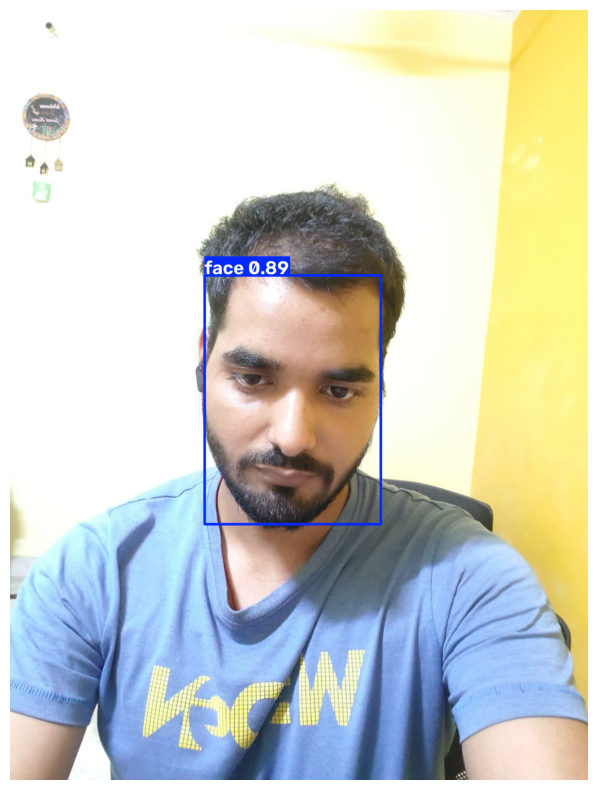

In [41]:
import matplotlib.pyplot as plt

annotated = result.plot()

plt.figure(figsize=(10, 10))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.show()

In [42]:
for i, box in enumerate(result.boxes):
    xyxy = box.xyxy[0].cpu().numpy()
    confidence = float(box.conf[0].cpu())
    class_id = int(box.cls[0].cpu())

    print(f"\nFace {i+1}")
    print("Bounding box:", xyxy)
    print("Confidence:", confidence)
    print("Class ID:", class_id)


Face 1
Bounding box: [     404.23      551.62      770.97      1068.7]
Confidence: 0.8861017823219299
Class ID: 0


In [43]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/drive/MyDrive/data")

records = []

for student_dir in sorted(DATA_DIR.iterdir()):

    if not student_dir.is_dir():
        continue

    student_id = student_dir.name

    for image_path in sorted(student_dir.iterdir()):

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        results = model.predict(
            source=str(image_path),
            conf=0.25,
            imgsz=640,
            device=0,
            verbose=False
        )

        result = results[0]

        face_count = len(result.boxes)

        if face_count > 0:
            confidences = result.boxes.conf.cpu().numpy()
            best_conf = float(max(confidences))

            # Largest detected face
            boxes = result.boxes.xyxy.cpu().numpy()
            areas = []

            for box in boxes:
                x1, y1, x2, y2 = box
                area = max(0, x2-x1) * max(0, y2-y1)
                areas.append(area)

            best_area = max(areas)

        else:
            best_conf = 0
            best_area = 0

        records.append({
            "student": student_id,
            "image": image_path.name,
            "faces_detected": face_count,
            "best_confidence": round(best_conf, 4),
            "largest_face_area": round(best_area, 0)
        })

df_detection = pd.DataFrame(records)

df_detection

,student,image,faces_detected,best_confidence,largest_face_area
0,stud001,WhatsApp Image 2026-09-21 at 18.55.22.jpeg,1,0.8760,167991.0
1,stud001,WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg,1,0.9182,162032.0
2,stud001,WhatsApp Image 2026-09-21 at 18.55.23.jpeg,1,0.8746,156503.0
3,stud002,img1.jpeg,1,0.9000,306771.0
4,stud002,img2.jpeg,1,0.8883,282087.0
5,stud002,img3.jpeg,1,0.8738,272415.0
6,stud002,img4.jpeg,1,0.8842,298749.0
7,stud002,img6.jpeg,1,0.8659,175600.0
8,stud002,img7.jpeg,1,0.8752,282923.0
9,stud002,img8.jpeg,1,0.9036,330998.0


In [44]:
print("Total images:", len(df_detection))
print("Images with faces:", (df_detection["faces_detected"] > 0).sum())
print("Images with no face:", (df_detection["faces_detected"] == 0).sum())

print("\nFaces detected per image:")
display(df_detection)

Total images: 19
Images with faces: 19
Images with no face: 0

Faces detected per image:


,student,image,faces_detected,best_confidence,largest_face_area
0,stud001,WhatsApp Image 2026-09-21 at 18.55.22.jpeg,1,0.8760,167991.0
1,stud001,WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg,1,0.9182,162032.0
2,stud001,WhatsApp Image 2026-09-21 at 18.55.23.jpeg,1,0.8746,156503.0
3,stud002,img1.jpeg,1,0.9000,306771.0
4,stud002,img2.jpeg,1,0.8883,282087.0
5,stud002,img3.jpeg,1,0.8738,272415.0
6,stud002,img4.jpeg,1,0.8842,298749.0
7,stud002,img6.jpeg,1,0.8659,175600.0
8,stud002,img7.jpeg,1,0.8752,282923.0
9,stud002,img8.jpeg,1,0.9036,330998.0


In [45]:
df_detection.groupby("student").agg(
    images=("image", "count"),
    successful=("faces_detected", lambda x: (x > 0).sum()),
    avg_confidence=("best_confidence", "mean"),
    min_confidence=("best_confidence", "min")
)

,images,successful,avg_confidence,min_confidence
student,,,,
stud001,3,3,0.889600,0.8746
stud002,8,8,0.883587,0.8659
stud003,8,8,0.885325,0.8751


Face 1
Crop size: (455, 356, 3)


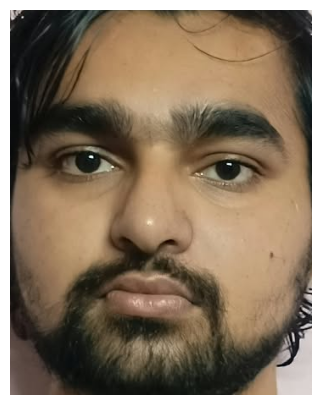

In [46]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

student_dir = DATA_DIR / "stud001"
image_path = next(student_dir.glob("*"))

result = model.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False
)[0]

image = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for i, box in enumerate(result.boxes.xyxy.cpu().numpy()):

    x1, y1, x2, y2 = map(int, box)

    face_crop = image_rgb[y1:y2, x1:x2]

    print(f"Face {i+1}")
    print("Crop size:", face_crop.shape)

    plt.figure(figsize=(5, 5))
    plt.imshow(face_crop)
    plt.axis("off")
    plt.show()

In [47]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image

DATA_DIR = Path("/content/drive/MyDrive/data")
CROP_DIR = Path("/content/face_crops")

CROP_DIR.mkdir(parents=True, exist_ok=True)

PADDING = 0.15

crop_records = []

for student_dir in sorted(DATA_DIR.iterdir()):

    if not student_dir.is_dir():
        continue

    student_id = student_dir.name

    student_crop_dir = CROP_DIR / student_id
    student_crop_dir.mkdir(parents=True, exist_ok=True)

    for image_path in sorted(student_dir.iterdir()):

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        # Run YOLO
        results = model.predict(
            source=str(image_path),
            conf=0.25,
            imgsz=640,
            device=0,
            verbose=False
        )

        result = results[0]

        if len(result.boxes) == 0:
            print(f"❌ No face: {image_path.name}")
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            print(f"❌ Could not read: {image_path}")
            continue

        h, w = image.shape[:2]

        # Select largest face
        boxes = result.boxes.xyxy.cpu().numpy()

        best_box = None
        best_area = 0

        for box in boxes:
            x1, y1, x2, y2 = box

            area = max(0, x2-x1) * max(0, y2-y1)

            if area > best_area:
                best_area = area
                best_box = box

        x1, y1, x2, y2 = best_box

        face_w = x2 - x1
        face_h = y2 - y1

        # 15% padding
        pad_x = face_w * PADDING
        pad_y = face_h * PADDING

        x1 = max(0, int(x1 - pad_x))
        y1 = max(0, int(y1 - pad_y))
        x2 = min(w, int(x2 + pad_x))
        y2 = min(h, int(y2 + pad_y))

        # Crop
        face_crop = image[y1:y2, x1:x2]

        # Save
        output_name = image_path.stem + "_face.jpg"
        output_path = student_crop_dir / output_name

        cv2.imwrite(str(output_path), face_crop)

        crop_records.append({
            "student": student_id,
            "original": image_path.name,
            "crop": str(output_path),
            "width": face_crop.shape[1],
            "height": face_crop.shape[0]
        })

        print(
            f"✅ {student_id} | "
            f"{image_path.name} → "
            f"{face_crop.shape[1]}x{face_crop.shape[0]}"
        )

print("\nTotal crops:", len(crop_records))

✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.22.jpeg → 431x658
✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg → 462x593
✅ stud001 | WhatsApp Image 2026-09-21 at 18.55.23.jpeg → 423x625
✅ stud002 | img1.jpeg → 655x792
✅ stud002 | img2.jpeg → 624x764
✅ stud002 | img3.jpeg → 577x763
✅ stud002 | img4.jpeg → 682x741
✅ stud002 | img6.jpeg → 510x581
✅ stud002 | img7.jpeg → 590x810
✅ stud002 | img8.jpeg → 683x819
✅ stud002 | ing5.jpeg → 599x696
✅ stud003 | WhatsApp Image 2026-09-21 at 22.47.25.jpeg → 433x634
✅ stud003 | img2.jpeg → 483x722
✅ stud003 | img3.jpeg → 430x603
✅ stud003 | img4.jpeg → 426x606
✅ stud003 | img5.jpeg → 453x631
✅ stud003 | img6.jpeg → 458x655
✅ stud003 | img7.jpeg → 460x637
✅ stud003 | img8.jpeg → 476x672

Total crops: 19


In [48]:
for p in sorted(CROP_DIR.rglob("*.jpg")):
    print(p)

/content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg
/content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg
/content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.23_face.jpg
/content/face_crops/stud002/img1_face.jpg
/content/face_crops/stud002/img2_face.jpg
/content/face_crops/stud002/img3_face.jpg
/content/face_crops/stud002/img4_face.jpg
/content/face_crops/stud002/img6_face.jpg
/content/face_crops/stud002/img7_face.jpg
/content/face_crops/stud002/img8_face.jpg
/content/face_crops/stud002/ing5_face.jpg
/content/face_crops/stud003/WhatsApp Image 2026-09-21 at 22.47.25_face.jpg
/content/face_crops/stud003/img2_face.jpg
/content/face_crops/stud003/img3_face.jpg
/content/face_crops/stud003/img4_face.jpg
/content/face_crops/stud003/img5_face.jpg
/content/face_crops/stud003/img6_face.jpg
/content/face_crops/stud003/img7_face.jpg
/content/face_crops/stud003/img8_face.jpg


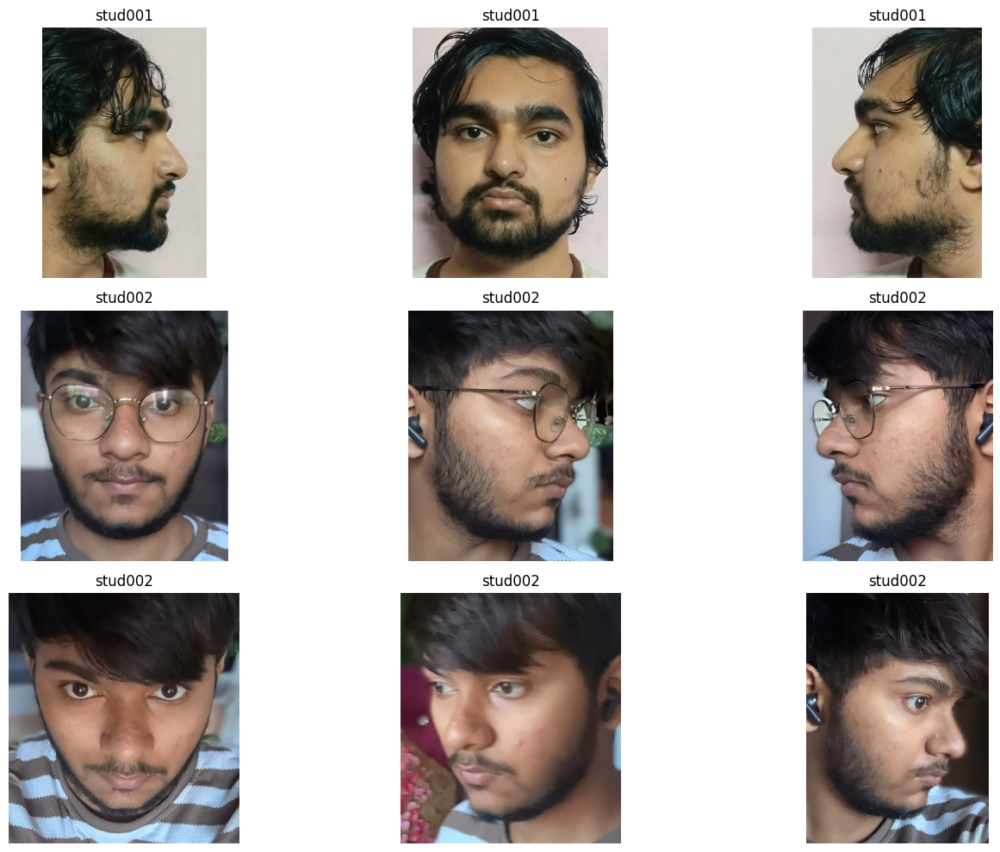

In [49]:
import matplotlib.pyplot as plt

crop_paths = sorted(CROP_DIR.rglob("*.jpg"))

plt.figure(figsize=(15, 10))

for i, path in enumerate(crop_paths[:9]):

    img = cv2.imread(str(path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [50]:
import insightface
import onnxruntime as ort

print("InsightFace:", insightface.__version__)
print("ONNX providers:", ort.get_available_providers())

InsightFace: 2.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


In [51]:

!pip install -q "onnxruntime-gpu==1.26.0"

In [52]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA: 12.8
CUDA available: True
GPU: Tesla T4


In [53]:
from insightface.app import FaceAnalysis

app = FaceAnalysis(
    name="buffalo_l",
    providers=[
        "CUDAExecutionProvider",
        "CPUExecutionProvider"
    ]
)

app.prepare(
    ctx_id=0,
    det_size=(640, 640)
)

print("InsightFace loaded successfully!")

InsightFace loaded successfully!


In [54]:
crop_paths = sorted(CROP_DIR.rglob("*.jpg"))

print("Number of face crops:", len(crop_paths))
print("Testing:", crop_paths[0])

Number of face crops: 19
Testing: /content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg


In [55]:
import cv2

test_crop = crop_paths[0]

img = cv2.imread(str(test_crop))

faces = app.get(img)

print("Faces detected:", len(faces))

Faces detected: 1


In [56]:
if len(faces) > 0:

    embedding = faces[0].embedding

    print("Embedding shape:", embedding.shape)
    print("Embedding dtype:", embedding.dtype)
    print("Embedding norm:", (embedding ** 2).sum() ** 0.5)
    print("First 10 values:")
    print(embedding[:10])

Embedding shape: (512,)
Embedding dtype: float32
Embedding norm: 22.621939
First 10 values:
[    0.63275      2.2444    -0.92946    -0.87425    -0.62331      1.8352     0.92413     0.68698      2.6374     0.36069]


**Using Faceinsight to get embedding**

In [57]:
import cv2
import numpy as np
from pathlib import Path

gallery = {}

for crop_path in sorted(CROP_DIR.rglob("*.jpg")):

    student_id = crop_path.parent.name

    img = cv2.imread(str(crop_path))

    if img is None:
        print(f"❌ Could not read: {crop_path}")
        continue

    faces = app.get(img)

    if len(faces) == 0:
        print(f"❌ No face from InsightFace: {crop_path}")
        continue

    # Use the strongest detected face
    face = max(
        faces,
        key=lambda f: float(f.det_score)
    )

    embedding = face.embedding.astype(np.float32)

    gallery.setdefault(student_id, []).append({
        "image": crop_path.name,
        "embedding": embedding,
        "det_score": float(face.det_score)
    })

print("\nGallery created!")

for student_id, samples in gallery.items():
    print(student_id, "→", len(samples), "embeddings")

❌ No face from InsightFace: /content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img1_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img2_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img3_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img4_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img6_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img7_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/img8_face.jpg
❌ No face from InsightFace: /content/face_crops/stud002/ing5_face.jpg
❌ No face from InsightFace: /content/face_crops/stud003/WhatsApp Image 2026-09-21 at 22.47.25_face.jpg
❌ No face from InsightFace: /content/face_crops/stud003/img2_face.jpg
❌ No face from InsightFace: /content/face_crops/stud003/img4_face.jpg
❌ No face from InsightFace: /content/face_crops/stud003/img5_face.jpg
❌ No face from Insig

**Finding why it fails for all images**

Crop shape: (792, 655, 3)


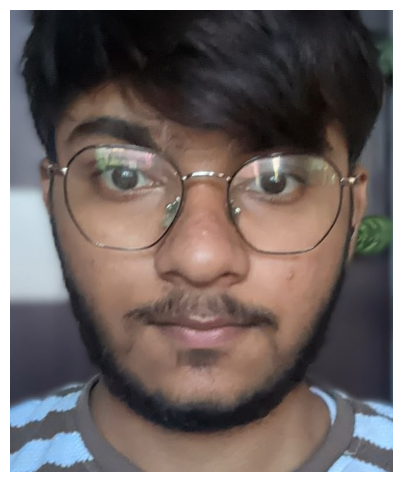

In [58]:
import cv2
import matplotlib.pyplot as plt

failed_crop = Path("/content/face_crops/stud002/img1_face.jpg")

img = cv2.imread(str(failed_crop))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Crop shape:", img_rgb.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

Successful crop shape: (658, 431, 3)


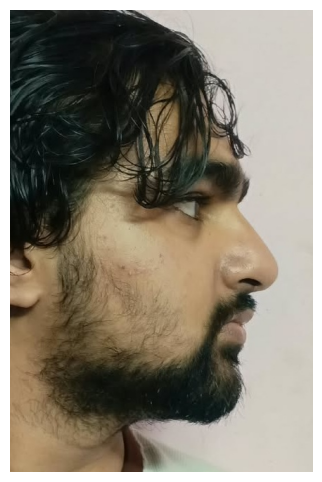

In [59]:
successful_crop = Path(
    "/content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg"
)

img = cv2.imread(str(successful_crop))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Successful crop shape:", img_rgb.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [60]:
for student_dir in sorted(CROP_DIR.iterdir()):

    if not student_dir.is_dir():
        continue

    print(f"\n===== {student_dir.name} =====")

    for p in sorted(student_dir.glob("*.jpg")):

        img = cv2.imread(str(p))

        print(
            p.name,
            "→",
            img.shape[1],
            "x",
            img.shape[0]
        )


===== stud001 =====
WhatsApp Image 2026-09-21 at 18.55.22_face.jpg → 431 x 658
WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg → 462 x 593
WhatsApp Image 2026-09-21 at 18.55.23_face.jpg → 423 x 625

===== stud002 =====
img1_face.jpg → 655 x 792
img2_face.jpg → 624 x 764
img3_face.jpg → 577 x 763
img4_face.jpg → 682 x 741
img6_face.jpg → 510 x 581
img7_face.jpg → 590 x 810
img8_face.jpg → 683 x 819
ing5_face.jpg → 599 x 696

===== stud003 =====
WhatsApp Image 2026-09-21 at 22.47.25_face.jpg → 433 x 634
img2_face.jpg → 483 x 722
img3_face.jpg → 430 x 603
img4_face.jpg → 426 x 606
img5_face.jpg → 453 x 631
img6_face.jpg → 458 x 655
img7_face.jpg → 460 x 637
img8_face.jpg → 476 x 672


***Resolving the issue***

In [61]:
print(app.models.keys())

dict_keys(['landmark_3d_68', 'landmark_2d_106', 'detection', 'genderage', 'recognition'])


In [62]:
for name, model_obj in app.models.items():
    print(name, type(model_obj))

landmark_3d_68 <class 'insightface.model_zoo.landmark.Landmark'>
landmark_2d_106 <class 'insightface.model_zoo.landmark.Landmark'>
detection <class 'insightface.model_zoo.scrfd.SCRFD'>
genderage <class 'insightface.model_zoo.attribute.Attribute'>
recognition <class 'insightface.model_zoo.arcface_onnx.ArcFaceONNX'>


In [63]:
print(app.models.keys())

for name, model_obj in app.models.items():
    print(name, type(model_obj))

dict_keys(['landmark_3d_68', 'landmark_2d_106', 'detection', 'genderage', 'recognition'])
landmark_3d_68 <class 'insightface.model_zoo.landmark.Landmark'>
landmark_2d_106 <class 'insightface.model_zoo.landmark.Landmark'>
detection <class 'insightface.model_zoo.scrfd.SCRFD'>
genderage <class 'insightface.model_zoo.attribute.Attribute'>
recognition <class 'insightface.model_zoo.arcface_onnx.ArcFaceONNX'>


In [83]:
import cv2
import numpy as np

test_crop = sorted(CROP_DIR.rglob("*.jpg"))[0]

img = cv2.imread(str(test_crop))

print("Image shape:", img.shape)

recognition_model = app.models["recognition"]

print("Recognition model:", type(recognition_model))

Image shape: (593, 462, 3)
Recognition model: <class 'insightface.model_zoo.arcface_onnx.ArcFaceONNX'>


In [84]:
print([x for x in dir(recognition_model) if not x.startswith("_")])

['compute_sim', 'forward', 'get', 'get_feat', 'input_mean', 'input_name', 'input_shape', 'input_size', 'input_std', 'model_file', 'output_names', 'output_shape', 'prepare', 'session', 'taskname']


In [85]:
recognition_model = app.models["recognition"]

print("Input shape:", recognition_model.input_shape)
print("Input size:", recognition_model.input_size)
print("Input mean:", recognition_model.input_mean)
print("Input std:", recognition_model.input_std)

Input shape: ['None', 3, 112, 112]
Input size: (112, 112)
Input mean: 127.5
Input std: 127.5


In [86]:
landmark_model = app.models["landmark_2d_106"]

print(type(landmark_model))
print([
    x for x in dir(landmark_model)
    if not x.startswith("_")
])

<class 'insightface.model_zoo.landmark.Landmark'>
['get', 'input_mean', 'input_name', 'input_shape', 'input_size', 'input_std', 'lmk_dim', 'lmk_num', 'model_file', 'output_names', 'prepare', 'require_pose', 'session', 'taskname']


In [87]:
from insightface.app.common import Face
import cv2
import numpy as np

# Use the same test crop
test_crop = sorted(CROP_DIR.rglob("*.jpg"))[0]

img = cv2.imread(str(test_crop))

h, w = img.shape[:2]

# Since this is already a YOLO face crop,
# treat the whole crop as the face bounding box.
face = Face(
    bbox=np.array([0, 0, w - 1, h - 1], dtype=np.float32)
)

print("Face bbox:", face.bbox)

Face bbox: [          0           0         430         657]


In [88]:
landmark_model = app.models["landmark_2d_106"]

landmarks = landmark_model.get(img, face)

print("Landmarks shape:", landmarks.shape)
print("First 5 landmarks:")
print(landmarks[:5])

Landmarks shape: (106, 2)
First 5 landmarks:
[[     314.83      554.72]
 [     49.855      287.11]
 [     125.68      521.59]
 [     149.67      537.24]
 [     175.88      549.44]]


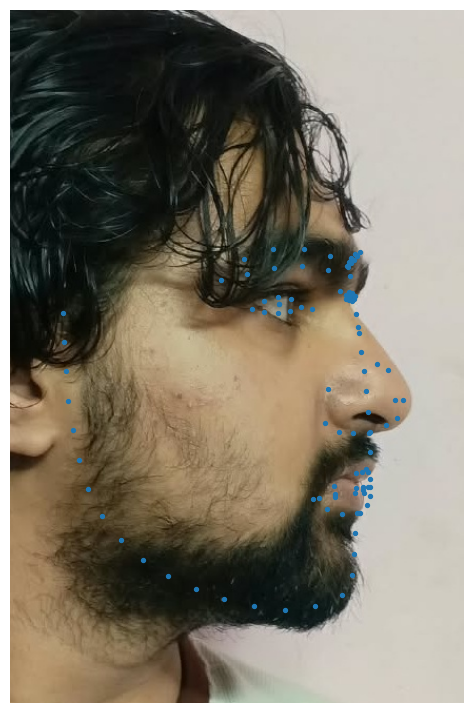

In [89]:
import matplotlib.pyplot as plt

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 9))
plt.imshow(img_rgb)

plt.scatter(
    landmarks[:, 0],
    landmarks[:, 1],
    s=8
)

plt.axis("off")
plt.show()

In [80]:
print("Landmark count:", landmark_model.lmk_num)
print("Landmark dimension:", landmark_model.lmk_dim)

Landmark count: 106
Landmark dimension: 2


In [81]:
print("Landmark output shape:", landmarks.shape)

Landmark output shape: (106, 2)


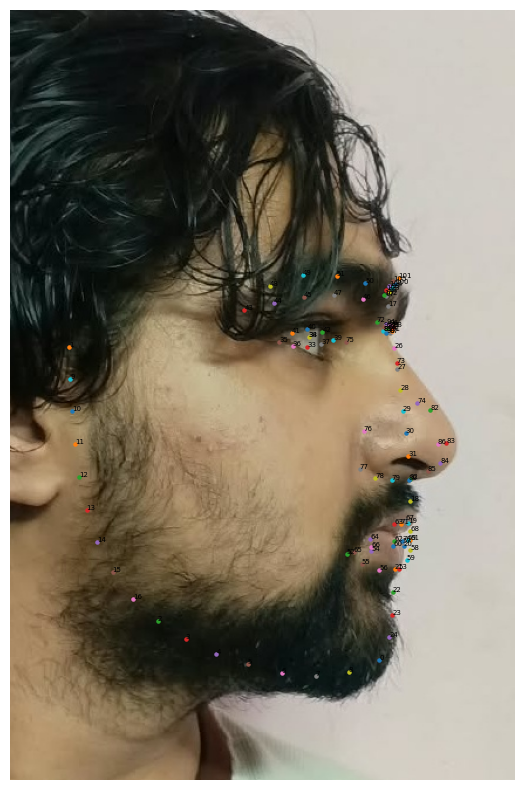

In [82]:
plt.figure(figsize=(8, 10))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

for i, (x, y) in enumerate(landmarks):
    plt.scatter(x, y, s=5)
    plt.text(x, y, str(i), fontsize=5)

plt.axis("off")
plt.show()

In [90]:
recognition_model = app.models["recognition"]

embedding = recognition_model.get_feat(img)

print("Embedding shape:", embedding.shape)
print("Embedding norm:", np.linalg.norm(embedding))

Embedding shape: (1, 512)
Embedding norm: 15.675465


In [297]:
# This cell previously created a temporary `gallery` variable for direct embedding evaluation.
# Its functionality is now largely covered by `initial_processed_embeddings` and `canonical_student_profiles`.
# This variable is considered obsolete in the new canonical gallery architecture.
# Removed to ensure all recognition paths use `canonical_student_profiles`.

In [298]:
# This cell previously performed pairwise comparisons using the temporary `gallery` variable.
# This variable is now obsolete, and this cell is removed as part of streamlining gallery management.

In [299]:
# This cell previously summarized similarity results from an obsolete gallery structure.
# It is now removed.

In [300]:
# This cell previously displayed similarity statistics from an obsolete gallery structure.
# It is now removed.

In [301]:
# This cell previously displayed a similarity histogram from an obsolete gallery structure.
# It is now removed.

In [97]:
!wget -q -O /content/lms_trans.py \
https://raw.githubusercontent.com/JDAI-CV/FaceX-Zoo/main/face_sdk/utils/lms_trans.py

print("Downloaded")

Downloaded


In [107]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from insightface.app.common import Face

# Pick one existing face crop
crop_path = crop_paths[0]

crop = cv2.imread(str(crop_path))

# Run YOLO face detector
results = model.predict(
    crop,
    conf=0.25,
    verbose=False
)

boxes = results[0].boxes.xyxy.cpu().numpy()

print("YOLO detected boxes:")
print(boxes)

YOLO detected boxes:
[[     45.219      92.951      383.55      576.08]]


In [108]:
bbox = boxes[0].astype(np.float32)

face = Face(
    bbox=bbox
)

landmarks = landmark_model.get(crop, face)

print("Landmarks shape:", landmarks.shape)
print("First 5 landmarks:")
print(landmarks[:5])

Landmarks shape: (106, 2)
First 5 landmarks:
[[     306.74      541.68]
 [     68.175      270.84]
 [      126.1      499.91]
 [     148.12       516.4]
 [     172.65      529.78]]


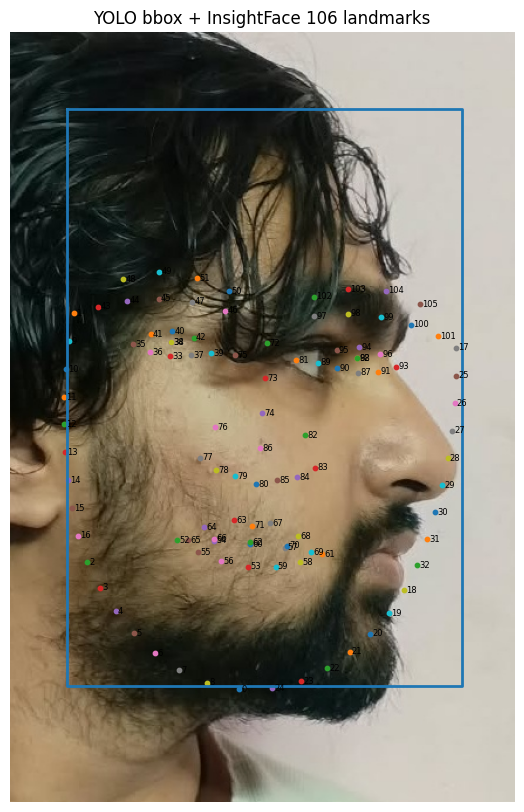

In [112]:
img_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 10))
plt.imshow(img_rgb)

for i, (x, y) in enumerate(landmarks):
    plt.scatter(x, y, s=10)
    plt.text(
        x + 2,
        y + 2,
        str(i),
        fontsize=6
    )

# Also show YOLO bbox
x1, y1, x2, y2 = bbox

plt.plot(
    [x1, x2, x2, x1, x1],
    [y1, y1, y2, y2, y1],
    linewidth=2
)

plt.axis("off")
plt.title("YOLO bbox + InsightFace 106 landmarks")
plt.show()

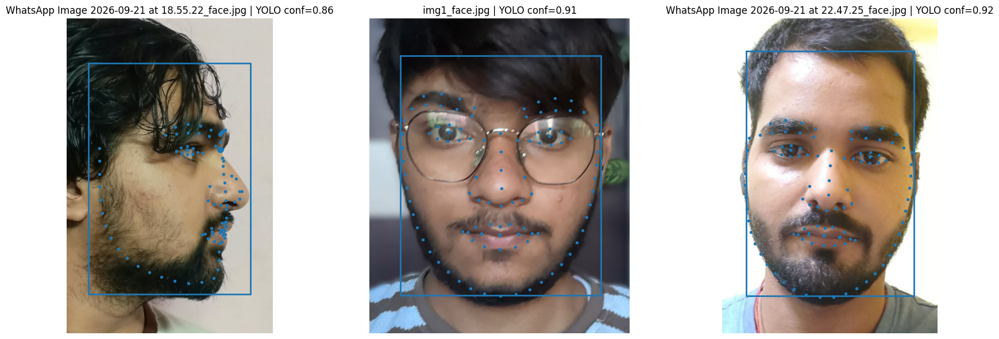

In [114]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from insightface.app.common import Face

base_dir = "/content/face_crops"

# Updated to use actual generated crop paths
test_images = [
    crop_paths[0], # Example: /content/face_crops/stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg
    crop_paths[3], # Example: /content/face_crops/stud002/img1_face.jpg
    crop_paths[11] # Example: /content/face_crops/stud003/WhatsApp Image 2026-09-21 at 22.47.25_face.jpg
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

# Ensure axes is iterable even if there's only one row/column
if not isinstance(axes, np.ndarray):
    axes = np.array([axes])

for ax, path in zip(axes.flat, test_images):

    # Convert Path object to string for cv2.imread
    image = cv2.imread(str(path))

    if image is None:
        ax.set_title(f"{os.path.basename(path)} - Failed to load")
        ax.axis("off")
        continue

    # -------------------------
    # 1. YOLO detection
    # -------------------------
    results = model.predict( # Fixed: changed yolo_model to model
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()

    if len(boxes) == 0:
        ax.set_title(f"{os.path.basename(path)} - NO FACE")
        ax.axis("off")
        continue

    # Pick highest confidence detection
    confidences = results[0].boxes.conf.cpu().numpy()
    best_idx = np.argmax(confidences)

    bbox = boxes[best_idx].astype(np.float32)

    # -------------------------
    # 2. InsightFace landmarks
    # -------------------------
    face = Face(bbox=bbox)

    landmarks = landmark_model.get(
        image,
        face
    )

    # -------------------------
    # 3. Plot
    # -------------------------
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(image_rgb)

    # YOLO bbox
    x1, y1, x2, y2 = bbox

    ax.plot(
        [x1, x2, x2, x1, x1],
        [y1, y1, y2, y2, y1],
        linewidth=2
    )

    # 106 landmarks
    ax.scatter(
        landmarks[:, 0],
        landmarks[:, 1],
        s=8
    )

    ax.set_title(
        f"{os.path.basename(path)} | "
        f"YOLO conf={confidences[best_idx]:.2f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [120]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from insightface.app.common import Face
from insightface.utils import face_align


# --------------------------------------------------
# IMAGE
# --------------------------------------------------

# Use an existing crop from the generated list
path = str(crop_paths[3])

image = cv2.imread(path)

if image is None:
    raise FileNotFoundError(path)


# --------------------------------------------------
# YOLO FACE DETECTION
# --------------------------------------------------

results = model.predict( # Fixed: Changed yolo_model to model
    image,
    conf=0.25,
    verbose=False
)

boxes = results[0].boxes.xyxy.cpu().numpy()
confidences = results[0].boxes.conf.cpu().numpy()

if len(boxes) == 0:
    raise RuntimeError("No face detected")


# Highest confidence face
best_idx = np.argmax(confidences)

bbox = boxes[best_idx].astype(np.float32)


# --------------------------------------------------
# INSIGHTFACE 106 LANDMARKS
# --------------------------------------------------

face = Face(bbox=bbox)

landmarks = landmark_model.get(
    image,
    face
)

print("Landmarks:", landmarks.shape)


# --------------------------------------------------
# SELECT 5 ARCface POINTS
# --------------------------------------------------

five_points = np.array([
    landmarks[38],   # eye 1
    landmarks[88],   # eye 2
    landmarks[86],   # nose
    landmarks[52],   # mouth corner 1
    landmarks[61],   # mouth corner 2
], dtype=np.float32)


print("\n5 landmarks:")
print(five_points)

Landmarks: (106, 2)

5 landmarks:
[[      199.9      284.83]
 [     451.19      295.02]
 [      330.9      427.07]
 [     232.63      535.76]
 [     422.56      539.77]]


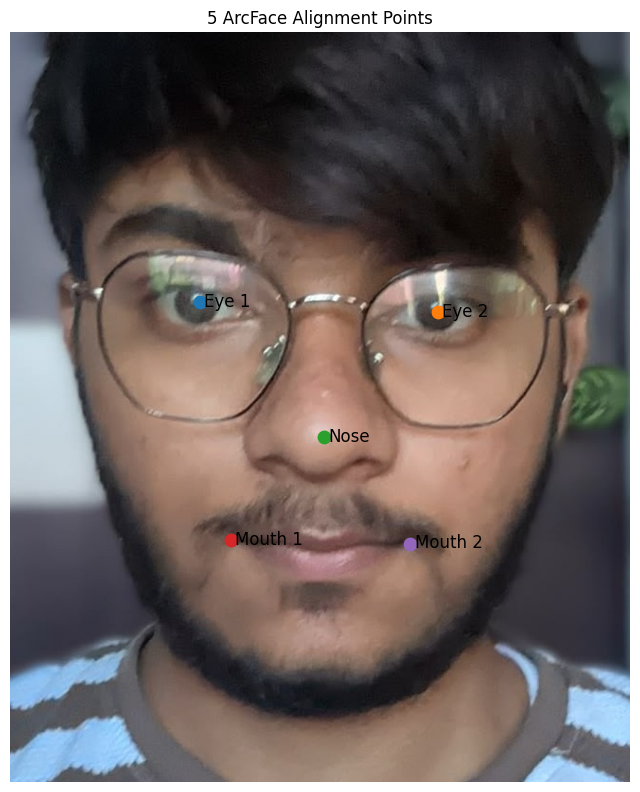

In [121]:
img_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 10))
plt.imshow(img_rgb)

labels = [
    "Eye 1",
    "Eye 2",
    "Nose",
    "Mouth 1",
    "Mouth 2"
]

for point, label in zip(five_points, labels):

    x, y = point

    plt.scatter(
        x,
        y,
        s=80
    )

    plt.text(
        x + 5,
        y + 5,
        label,
        fontsize=12
    )

plt.axis("off")
plt.title("5 ArcFace Alignment Points")
plt.show()

In [122]:
aligned = face_align.norm_crop(
    image,
    landmark=five_points,
    image_size=112
)

print("Aligned shape:", aligned.shape)

Aligned shape: (112, 112, 3)


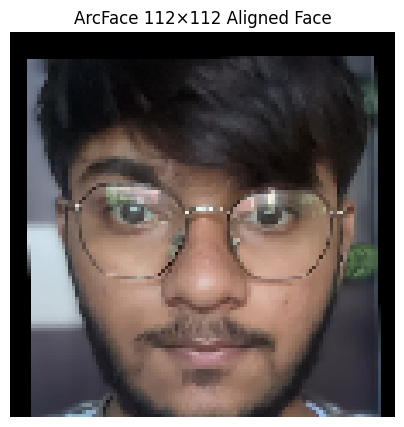

In [123]:
aligned_rgb = cv2.cvtColor(
    aligned,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(5, 5))

plt.imshow(aligned_rgb)

plt.axis("off")

plt.title("ArcFace 112×112 Aligned Face")

plt.show()

In [126]:
import cv2
import numpy as np

from insightface.app.common import Face
from insightface.utils import face_align


def get_aligned_embedding(image):
    """
    YOLO → 106 landmarks → 5 points → ArcFace alignment → embedding
    """

    # -----------------------------
    # 1. YOLO face detection
    # -----------------------------
    results = model.predict( # Changed yolo_model to model
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()

    if len(boxes) == 0:
        return None

    # Highest-confidence face
    confidences = results[0].boxes.conf.cpu().numpy()
    best_idx = np.argmax(confidences)

    bbox = boxes[best_idx].astype(np.float32)

    # -----------------------------
    # 2. 106 landmarks
    # -----------------------------
    face = Face(bbox=bbox)

    landmarks = landmark_model.get(
        image,
        face
    )

    # -----------------------------
    # 3. Five alignment points
    # -----------------------------
    five_points = np.array([
        landmarks[38],
        landmarks[88],
        landmarks[86],
        landmarks[52],
        landmarks[61]
    ], dtype=np.float32)

    # -----------------------------
    # 4. ArcFace alignment
    # -----------------------------
    aligned = face_align.norm_crop(
        image,
        landmark=five_points,
        image_size=112
    )

    # -----------------------------
    # 5. ArcFace embedding
    # -----------------------------
    embedding = recognition_model.get_feat(aligned)[0]

    # L2 normalize
    embedding = embedding / (
        np.linalg.norm(embedding) + 1e-12
    )

    return embedding

In [127]:

test_path = str(crop_paths[3])



test_img = cv2.imread(test_path)

embedding = get_aligned_embedding(test_img)

print("Embedding shape:", embedding.shape)
print("Embedding norm:", np.linalg.norm(embedding))
print("First 10 values:", embedding[:10])

Embedding shape: (512,)
Embedding norm: 1.0
First 10 values: [    0.05716      0.1064    -0.00214   -0.020325    0.038327   -0.060518  -0.0065674    0.036332   -0.062745    0.086545]


In [290]:
import os

dataset_dir = "/content/face_crops"

# This `embeddings` variable will be used to initialize the `all_embeddings` which then feeds `student_profiles`.
# Renaming to avoid confusion with the `gallery` variable in the previous cell.
initial_processed_embeddings = {}
failed = []

for student_id in sorted(os.listdir(dataset_dir)):

    student_dir = os.path.join(
        dataset_dir,
        student_id
    )

    if not os.path.isdir(student_dir):
        continue

    initial_processed_embeddings[student_id] = {}

    for filename in sorted(os.listdir(student_dir)):

        path = os.path.join(
            student_dir,
            filename
        )

        image = cv2.imread(path)

        if image is None:
            failed.append(path)
            continue

        emb = get_aligned_embedding(image)

        if emb is None:
            failed.append(path)
            continue

        initial_processed_embeddings[student_id][filename] = emb

        print(
            f"✓ {student_id}/{filename}"
        )

print("\n====================")
print("INITIAL PROCESSED EMBEDDINGS RESULT")
print("====================")

for student_id, imgs in initial_processed_embeddings.items():
    print(
        student_id,
        "→",
        len(imgs),
        "embeddings"
    )

print("Failed:", len(failed))

if failed:
    print("\nFailed files:")
    for f in failed:
        print(f)


✓ stud001/WhatsApp Image 2026-09-21 at 18.55.22_face.jpg
✓ stud001/WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg
✓ stud001/WhatsApp Image 2026-09-21 at 18.55.23_face.jpg
✓ stud002/img1_face.jpg
✓ stud002/img2_face.jpg
✓ stud002/img3_face.jpg
✓ stud002/img4_face.jpg
✓ stud002/img6_face.jpg
✓ stud002/img7_face.jpg
✓ stud002/img8_face.jpg
✓ stud002/ing5_face.jpg
✓ stud003/WhatsApp Image 2026-09-21 at 22.47.25_face.jpg
✓ stud003/img2_face.jpg
✓ stud003/img3_face.jpg
✓ stud003/img4_face.jpg
✓ stud003/img5_face.jpg
✓ stud003/img6_face.jpg
✓ stud003/img7_face.jpg
✓ stud003/img8_face.jpg

INITIAL PROCESSED EMBEDDINGS RESULT
stud001 → 3 embeddings
stud002 → 8 embeddings
stud003 → 8 embeddings
Failed: 0


In [129]:
import pickle

with open(
    "/content/face_embeddings_aligned.pkl",
    "wb"
) as f:
    pickle.dump(embeddings, f)

print("Saved successfully.")

Saved successfully.


In [130]:
import numpy as np
import pandas as pd
from itertools import combinations


# ==========================================
# CREATE FLAT LIST
# ==========================================

samples = []

for student_id, image_dict in embeddings.items():

    for filename, embedding in image_dict.items():

        samples.append({
            "student_id": student_id,
            "filename": filename,
            "embedding": embedding
        })


print("Total embeddings:", len(samples))


# ==========================================
# PAIRWISE COMPARISON
# ==========================================

results = []

for a, b in combinations(samples, 2):

    emb1 = a["embedding"]
    emb2 = b["embedding"]

    # Cosine similarity
    similarity = float(
        np.dot(emb1, emb2)
    )

    same_person = (
        a["student_id"] == b["student_id"]
    )

    results.append({
        "student_1": a["student_id"],
        "image_1": a["filename"],
        "student_2": b["student_id"],
        "image_2": b["filename"],
        "similarity": similarity,
        "same_person": same_person
    })


df = pd.DataFrame(results)

print("\nTotal comparisons:", len(df))

print(
    df["same_person"]
    .value_counts()
)

Total embeddings: 19

Total comparisons: 171
same_person
False    112
True      59
Name: count, dtype: int64


In [131]:
same = df[df["same_person"] == True]["similarity"]
different = df[df["same_person"] == False]["similarity"]


print("================================")
print("SAME PERSON")
print("================================")

print("Count :", len(same))
print("Min   :", same.min())
print("Mean  :", same.mean())
print("Median:", same.median())
print("Max   :", same.max())
print("Std   :", same.std())


print("\n================================")
print("DIFFERENT PERSON")
print("================================")

print("Count :", len(different))
print("Min   :", different.min())
print("Mean  :", different.mean())
print("Median:", different.median())
print("Max   :", different.max())
print("Std   :", different.std())

SAME PERSON
Count : 59
Min   : 0.5155221223831177
Mean  : 0.703368207155648
Median: 0.6943768262863159
Max   : 0.9441453218460083
Std   : 0.09383070531838077

DIFFERENT PERSON
Count : 112
Min   : 0.0034105107188224792
Mean  : 0.14804259288523877
Median: 0.150835283100605
Max   : 0.25447311997413635
Std   : 0.04336063438036383


In [132]:
print("TOP DIFFERENT-PERSON MATCHES")
print("--------------------------------")

print(
    df[df["same_person"] == False]
    .sort_values("similarity", ascending=False)
    .head(10)
    .to_string(index=False)
)

TOP DIFFERENT-PERSON MATCHES
--------------------------------
student_1                                            image_1 student_2       image_2  similarity  same_person
  stud001     WhatsApp Image 2026-09-21 at 18.55.23_face.jpg   stud003 img7_face.jpg    0.254473        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.23_face.jpg   stud003 img3_face.jpg    0.247864        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.22_face.jpg   stud003 img7_face.jpg    0.232713        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.22_face.jpg   stud003 img4_face.jpg    0.215276        False
  stud001 WhatsApp Image 2026-09-21 at 18.55.23 (1)_face.jpg   stud002 img4_face.jpg    0.215150        False
  stud002                                      img4_face.jpg   stud003 img5_face.jpg    0.214132        False
  stud002                                      img7_face.jpg   stud003 img5_face.jpg    0.207698        False
  stud001     WhatsApp Image 2026-09-21 at 18.55.22_face.j

In [133]:
print("\nLOWEST SAME-PERSON MATCHES")
print("--------------------------------")

print(
    df[df["same_person"] == True]
    .sort_values("similarity")
    .head(10)
    .to_string(index=False)
)


LOWEST SAME-PERSON MATCHES
--------------------------------
student_1                                            image_1 student_2                                        image_2  similarity  same_person
  stud002                                      img3_face.jpg   stud002                                  img7_face.jpg    0.515522         True
  stud002                                      img3_face.jpg   stud002                                  ing5_face.jpg    0.516477         True
  stud002                                      img3_face.jpg   stud002                                  img4_face.jpg    0.542435         True
  stud002                                      img4_face.jpg   stud002                                  ing5_face.jpg    0.562389         True
  stud002                                      img3_face.jpg   stud002                                  img8_face.jpg    0.568975         True
  stud002                                      img3_face.jpg   stud002           

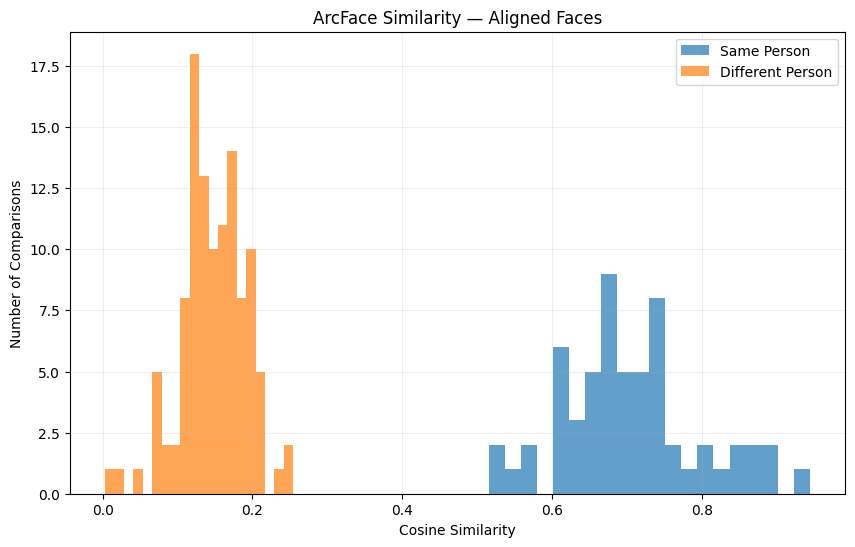

In [134]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    same,
    bins=20,
    alpha=0.7,
    label="Same Person"
)

plt.hist(
    different,
    bins=20,
    alpha=0.7,
    label="Different Person"
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Number of Comparisons")

plt.title(
    "ArcFace Similarity — Aligned Faces"
)

plt.legend()

plt.grid(alpha=0.2)

plt.show()

In [135]:
df.to_csv(
    "/content/aligned_arcface_similarity_results.csv",
    index=False
)

print(
    "Saved: /content/aligned_arcface_similarity_results.csv"
)

Saved: /content/aligned_arcface_similarity_results.csv


In [137]:
import numpy as np
import pandas as pd

thresholds = np.arange(
    0.20,
    0.61,
    0.01
)

threshold_results = []

for threshold in thresholds:

    # Predict same person if similarity >= threshold
    predicted_same = (
        df["similarity"] >= threshold
    )

    actual_same = df["same_person"]

    TP = np.sum(
        predicted_same & actual_same
    )

    TN = np.sum(
        (~predicted_same) & (~actual_same)
    )

    FP = np.sum(
        predicted_same & (~actual_same)
    )

    FN = np.sum(
        (~predicted_same) & actual_same
    )

    FAR = FP / (FP + TN) if (FP + TN) else 0
    FRR = FN / (FN + TP) if (FN + TP) else 0

    accuracy = (
        TP + TN
    ) / len(df)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "TP": TP,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "FAR": FAR,
        "FRR": FRR,
        "accuracy": accuracy
    })


threshold_df = pd.DataFrame(
    threshold_results
)

print(
    threshold_df.to_string(index=False)
)

 threshold  TP  TN  FP  FN      FAR      FRR  accuracy
      0.20  59 104   8   0 0.071429 0.000000  0.953216
      0.21  59 106   6   0 0.053571 0.000000  0.964912
      0.22  59 109   3   0 0.026786 0.000000  0.982456
      0.23  59 109   3   0 0.026786 0.000000  0.982456
      0.24  59 110   2   0 0.017857 0.000000  0.988304
      0.25  59 111   1   0 0.008929 0.000000  0.994152
      0.26  59 112   0   0 0.000000 0.000000  1.000000
      0.27  59 112   0   0 0.000000 0.000000  1.000000
      0.28  59 112   0   0 0.000000 0.000000  1.000000
      0.29  59 112   0   0 0.000000 0.000000  1.000000
      0.30  59 112   0   0 0.000000 0.000000  1.000000
      0.31  59 112   0   0 0.000000 0.000000  1.000000
      0.32  59 112   0   0 0.000000 0.000000  1.000000
      0.33  59 112   0   0 0.000000 0.000000  1.000000
      0.34  59 112   0   0 0.000000 0.000000  1.000000
      0.35  59 112   0   0 0.000000 0.000000  1.000000
      0.36  59 112   0   0 0.000000 0.000000  1.000000
      0.37

In [138]:
perfect = threshold_df[
    (threshold_df["FAR"] == 0) &
    (threshold_df["FRR"] == 0)
]

print("\nPerfect thresholds:")
print(perfect.to_string(index=False))


Perfect thresholds:
 threshold  TP  TN  FP  FN  FAR  FRR  accuracy
      0.26  59 112   0   0  0.0  0.0       1.0
      0.27  59 112   0   0  0.0  0.0       1.0
      0.28  59 112   0   0  0.0  0.0       1.0
      0.29  59 112   0   0  0.0  0.0       1.0
      0.30  59 112   0   0  0.0  0.0       1.0
      0.31  59 112   0   0  0.0  0.0       1.0
      0.32  59 112   0   0  0.0  0.0       1.0
      0.33  59 112   0   0  0.0  0.0       1.0
      0.34  59 112   0   0  0.0  0.0       1.0
      0.35  59 112   0   0  0.0  0.0       1.0
      0.36  59 112   0   0  0.0  0.0       1.0
      0.37  59 112   0   0  0.0  0.0       1.0
      0.38  59 112   0   0  0.0  0.0       1.0
      0.39  59 112   0   0  0.0  0.0       1.0
      0.40  59 112   0   0  0.0  0.0       1.0
      0.41  59 112   0   0  0.0  0.0       1.0
      0.42  59 112   0   0  0.0  0.0       1.0
      0.43  59 112   0   0  0.0  0.0       1.0
      0.44  59 112   0   0  0.0  0.0       1.0
      0.45  59 112   0   0  0.0  0.0   

In [139]:
threshold_df["error_gap"] = abs(
    threshold_df["FAR"] -
    threshold_df["FRR"]
)

eer_row = threshold_df.loc[
    threshold_df["error_gap"].idxmin()
]

print("Approximate EER threshold:")
print(eer_row)

Approximate EER threshold:
threshold      0.26
TP            59.00
TN           112.00
FP             0.00
FN             0.00
FAR            0.00
FRR            0.00
accuracy       1.00
error_gap      0.00
Name: 6, dtype: float64


In [302]:
# This cell previously created a mean-embedding `gallery` variable, which conflicts with the canonical `student_profiles`.
# It is now removed to maintain a single source of truth for enrolled students.

In [303]:
# ============================================
# RECOGNITION USING ENROLLED STUDENT PROFILES
# ============================================

RECOGNITION_THRESHOLD = 0.40

def recognize_enrolled_students(
    image,
    canonical_student_profiles,
    threshold=RECOGNITION_THRESHOLD
):
    """
    Detect all faces → landmarks → alignment → ArcFace
    → compare against all enrolled student embeddings.
    """

    # ----------------------------------------
    # 1. YOLO face detection
    # ----------------------------------------

    results = model.predict(
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()
    confidences = results[0].boxes.conf.cpu().numpy()

    if len(boxes) == 0:
        return []

    recognized_faces = []

    # ----------------------------------------
    # 2. Process every detected face
    # ----------------------------------------

    for i, bbox in enumerate(boxes):

        bbox = bbox.astype(np.float32)

        # ----------------------------------------
        # 3. InsightFace Face object
        # ----------------------------------------

        face = Face(bbox=bbox)

        # ----------------------------------------
        # 4. 106 landmarks
        # ----------------------------------------

        landmarks = landmark_model.get(
            image,
            face
        )

        if landmarks is None:
            continue

        # ----------------------------------------
        # 5. Five-point alignment
        # ----------------------------------------

        five_points = np.array([
            landmarks[38],
            landmarks[88],
            landmarks[86],
            landmarks[52],
            landmarks[61]
        ], dtype=np.float32)

        aligned = face_align.norm_crop(
            image,
            landmark=five_points,
            image_size=112
        )

        # ----------------------------------------
        # 6. ArcFace embedding
        # ----------------------------------------

        embedding = recognition_model.get_feat(
            aligned
        )[0]

        embedding = embedding / (
            np.linalg.norm(embedding) + 1e-12
        )

        # ----------------------------------------
        # 7. Compare against enrolled students
        # ----------------------------------------

        student_scores = {}

        for student_id, profile in canonical_student_profiles.items():

            enrolled_embeddings = (
                profile["embeddings"].values()
            )

            student_similarity_scores = []

            for enrolled_embedding in enrolled_embeddings:

                similarity = float(
                    np.dot(
                        embedding,
                        enrolled_embedding
                    )
                )

                student_similarity_scores.append(
                    similarity
                )

            if student_similarity_scores:

                # Best matching enrollment image
                student_scores[student_id] = max(
                    student_similarity_scores
                )

        # ----------------------------------------
        # 8. No enrolled students
        # ----------------------------------------

        if not student_scores:
            continue

        # ----------------------------------------
        # 9. Find best student
        # ----------------------------------------

        best_student = max(
            student_scores,
            key=student_scores.get
        )

        best_score = student_scores[best_student]

        # ----------------------------------------
        # 10. Threshold decision
        # ----------------------------------------

        if best_score >= threshold:

            identity = best_student
            status = "RECOGNIZED"

        else:

            identity = "UNKNOWN"
            status = "UNKNOWN"

        # ----------------------------------------
        # 11. Store result
        # ----------------------------------------

        recognized_faces.append({

            "bbox": bbox,

            "identity": identity,

            "score": best_score,

            "status": status,

            "detector_confidence": float(
                confidences[i]
            ),

            "scores": student_scores
        })

    return recognized_faces

In [155]:
import cv2

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError(
        "Could not open webcam"
    )

ret, frame = cap.read()

cap.release()

print("Camera working:", ret)

if ret:
    print("Frame shape:", frame.shape)

RuntimeError: Could not open webcam

## Live Webcam Access using JavaScript

Since Python running on Colab's servers cannot directly access your local webcam, we'll use JavaScript to capture frames and send them back to the Python kernel.

In [159]:
# ============================================
# STEP 3 — CAPTURE ONE FRAME FROM COLAB WEBCAM
# ============================================

from IPython.display import display, Javascript
from google.colab.output import eval_js
import base64
import cv2
import numpy as np


def capture_webcam_frame():

    js_code = """
    async function captureFrame() {

        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        video.style.display = 'block';

        button.innerHTML = 'Capture Frame';
        button.style.fontSize = '18px';
        button.style.padding = '10px 20px';
        button.style.marginTop = '10px';

        const stream =
            await navigator.mediaDevices.getUserMedia({
                video: true
            });

        document.body.appendChild(div);

        div.appendChild(video);
        div.appendChild(button);

        video.srcObject = stream;

        await video.play();

        google.colab.output.setIframeHeight(
            document.documentElement.scrollHeight,
            true
        );

        return new Promise((resolve) => {

            button.onclick = () => {

                const canvas =
                    document.createElement('canvas');

                canvas.width = video.videoWidth;
                canvas.height = video.videoHeight;

                const context =
                    canvas.getContext('2d');

                context.drawImage(
                    video,
                    0,
                    0,
                    canvas.width,
                    canvas.height
                );

                stream
                    .getVideoTracks()[0]
                    .stop();

                div.remove();

                resolve(
                    canvas.toDataURL('image/jpeg')
                );
            };
        });
    }

    captureFrame();
    """

    display(
        Javascript(js_code)
    )

    # Wait for Capture Frame button
    data = eval_js(
        'captureFrame()'
    )

    # ----------------------------------------
    # Decode Base64
    # ----------------------------------------

    binary_data = base64.b64decode(
        data.split(',')[1]
    )

    # ----------------------------------------
    # Convert to OpenCV image
    # ----------------------------------------

    np_arr = np.frombuffer(
        binary_data,
        dtype=np.uint8
    )

    frame = cv2.imdecode(
        np_arr,
        cv2.IMREAD_COLOR
    )

    return frame

In [323]:
# ============================================
# STEP 4 — TEST WEBCAM CAPTURE
# ============================================

webcam_frame = capture_webcam_frame()

if webcam_frame is not None:

    print("✅ Webcam frame captured!")

    print(
        "Frame shape:",
        webcam_frame.shape
    )

else:

    print(
        "❌ Failed to capture webcam frame"
    )

<IPython.core.display.Javascript object>

✅ Webcam frame captured!
Frame shape: (480, 640, 3)


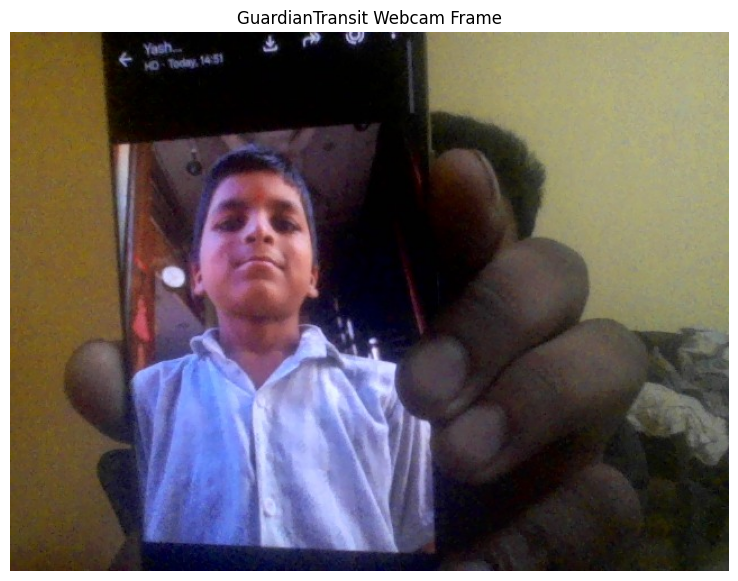

In [324]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(
    cv2.cvtColor(
        webcam_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("GuardianTransit Webcam Frame")

plt.show()

In [325]:
# Alias recognize_enrolled_students for single face recognition for backward compatibility or clarity.
# This function will now use the canonical_student_profiles.
def recognize_face(image, threshold=RECOGNITION_THRESHOLD):
    results = recognize_enrolled_students(image, canonical_student_profiles, threshold)
    # Assuming only one face for 'recognize_face' for simplicity, or pick the highest score
    if results:
        return max(results, key=lambda x: x['score'])
    return None

result = recognize_face(
    webcam_frame
)

print(result)

{'bbox': array([     169.68,      125.26,       269.1,      247.79], dtype=float32), 'identity': 'stud004', 'score': 0.8963810205459595, 'status': 'RECOGNIZED', 'detector_confidence': 0.8713487982749939, 'scores': {'stud001': 0.09121279418468475, 'stud002': 0.14301855862140656, 'stud003': 0.09977628290653229, 'stud004': 0.8963810205459595, 'stud005': 0.26521092653274536}}


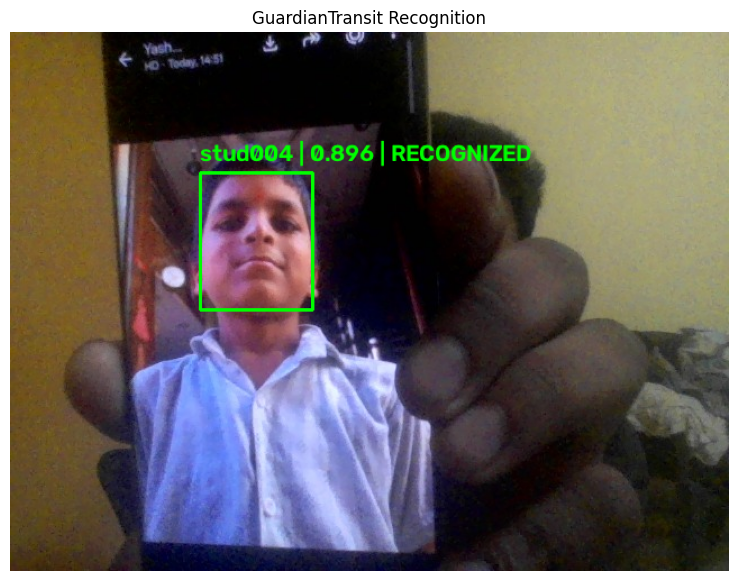

In [326]:
display_frame = webcam_frame.copy()

if result is not None:

    x1, y1, x2, y2 = (
        result["bbox"].astype(int)
    )

    identity = result["identity"]
    score = result["score"]
    status = result["status"]

    # Bounding box
    cv2.rectangle(
        display_frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    # Label
    label = (
        f"{identity} | "
        f"{score:.3f} | "
        f"{status}"
    )

    cv2.putText(
        display_frame,
        label,
        (x1, max(y1 - 10, 30)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (0, 255, 0),
        2
    )

else:

    cv2.putText(
        display_frame,
        "NO FACE",
        (30, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        2
    )


plt.figure(figsize=(10, 7))

plt.imshow(
    cv2.cvtColor(
        display_frame,
        cv2.COLOR_BGR2RGB
    )
)

plt.axis("off")
plt.title("GuardianTransit Recognition")

plt.show()

# Multi Face Detection


In [218]:
import cv2
import numpy as np
from insightface.app.common import Face
from insightface.utils import face_align

In [305]:
def recognize_multiple_faces(image, threshold=RECOGNITION_THRESHOLD):

    results = model.predict(
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()
    confidences = results[0].boxes.conf.cpu().numpy()

    if len(boxes) == 0:
        return []

    recognized_faces = []

    for i, bbox in enumerate(boxes):

        bbox = bbox.astype(np.float32)

        # Create InsightFace Face object
        face = Face(bbox=bbox)

        # Get 106 landmarks
        landmarks = landmark_model.get(image, face)

        if landmarks is None:
            continue

        # Select the 5 points we already validated
        five_points = np.array([
            landmarks[38],
            landmarks[88],
            landmarks[86],
            landmarks[52],
            landmarks[61]
        ], dtype=np.float32)

        # Align face
        aligned = face_align.norm_crop(
            image,
            landmark=five_points,
            image_size=112
        )

        # ArcFace embedding
        embedding = recognition_model.get_feat(aligned)[0]

        # Normalize
        embedding = embedding / (
            np.linalg.norm(embedding) + 1e-12
        )

        # Compare with canonical_student_profiles
        scores = {}

        for student_id, profile in canonical_student_profiles.items():
            enrolled_embeddings = profile["embeddings"].values()
            student_similarity_scores = []
            for enrolled_embedding in enrolled_embeddings:
                similarity = float(
                    np.dot(embedding, enrolled_embedding)
                )
                student_similarity_scores.append(similarity)

            if student_similarity_scores:
                scores[student_id] = max(student_similarity_scores)

        # Best student
        best_student = max(
            scores,
            key=scores.get
        )

        best_score = scores[best_student]

        # Identity decision
        if best_score >= threshold:
            identity = best_student
            status = "RECOGNIZED"
        else:
            identity = "UNKNOWN"
            status = "UNKNOWN"

        recognized_faces.append({
            "bbox": bbox,
            "identity": identity,
            "score": best_score,
            "status": status,
            "detector_confidence": float(confidences[i]),
            "scores": scores
        })

    return recognized_faces

In [228]:
results = recognize_multiple_faces(webcam_frame)

print("Faces detected:", len(results))

for i, result in enumerate(results):

    print(
        f"Face {i+1}: "
        f"{result['identity']} | "
        f"Score: {result['score']:.3f} | "
        f"Status: {result['status']}"
    )

Faces detected: 4
Face 1: stud003 | Score: 0.506 | Status: RECOGNIZED
Face 2: stud001 | Score: 0.481 | Status: RECOGNIZED
Face 3: stud002 | Score: 0.406 | Status: RECOGNIZED
Face 4: UNKNOWN | Score: 0.091 | Status: UNKNOWN


In [221]:
def draw_recognition_results(image, results):

    output = image.copy()

    for result in results:

        x1, y1, x2, y2 = result["bbox"].astype(int)

        identity = result["identity"]
        score = result["score"]
        status = result["status"]

        # Bounding box
        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Label
        label = f"{identity} | {score:.2f}"

        cv2.putText(
            output,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    return output

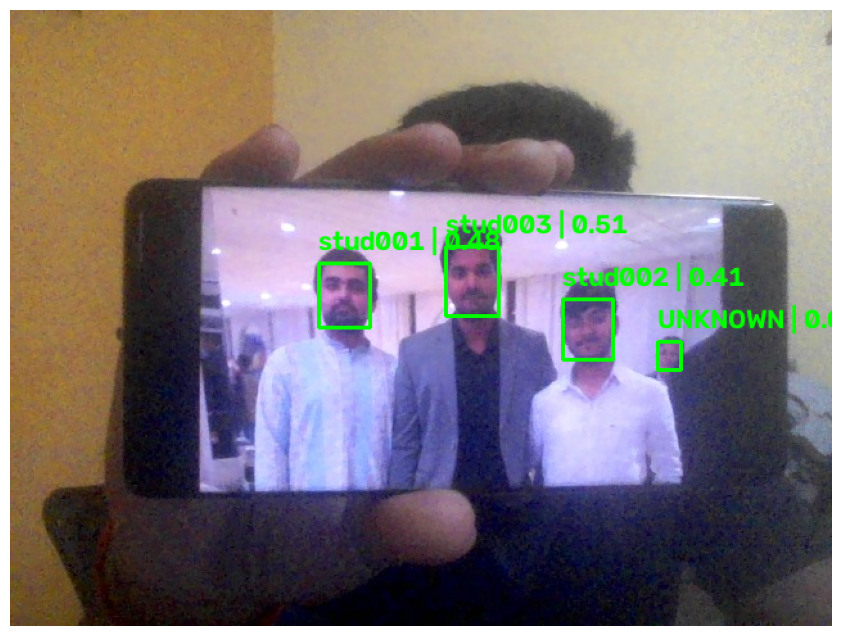

In [229]:
annotated = draw_recognition_results(
    webcam_frame,
    results
)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

**Live conitunous detection**

In [236]:
from google.colab import output
from IPython.display import display, Javascript
import base64
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

In [237]:

def live_face_test():

    js = """
    async function startLiveTest() {

        const container = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        video.style.width = '640px';
        video.style.display = 'block';

        button.innerText = 'Stop Live Detection';

        container.appendChild(video);
        container.appendChild(button);
        document.body.appendChild(container);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        let stopped = false;

        button.onclick = () => {
            stopped = true;
            stream.getTracks().forEach(track => track.stop());
            container.remove();
        };

        while (!stopped) {

            const canvas = document.createElement('canvas');

            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;

            canvas.getContext('2d').drawImage(
                video,
                0,
                0,
                canvas.width,
                canvas.height
            );

            const image =
                canvas.toDataURL('image/jpeg', 0.75);

            google.colab.kernel.invokeFunction(
                'guardian.receive_frame',
                [image],
                {}
            );

            await new Promise(
                resolve => setTimeout(resolve, 1000)
            );
        }
    }

    startLiveTest();
    """

    display(Javascript(js))

In [238]:
latest_live_frame = None

def receive_live_frame(data):

    global latest_live_frame

    binary = base64.b64decode(
        data.split(",")[1]
    )

    arr = np.frombuffer(
        binary,
        dtype=np.uint8
    )

    latest_live_frame = cv2.imdecode(
        arr,
        cv2.IMREAD_COLOR
    )


output.register_callback(
    'guardian.receive_frame',
    receive_live_frame
)

In [241]:
live_face_test()

<IPython.core.display.Javascript object>

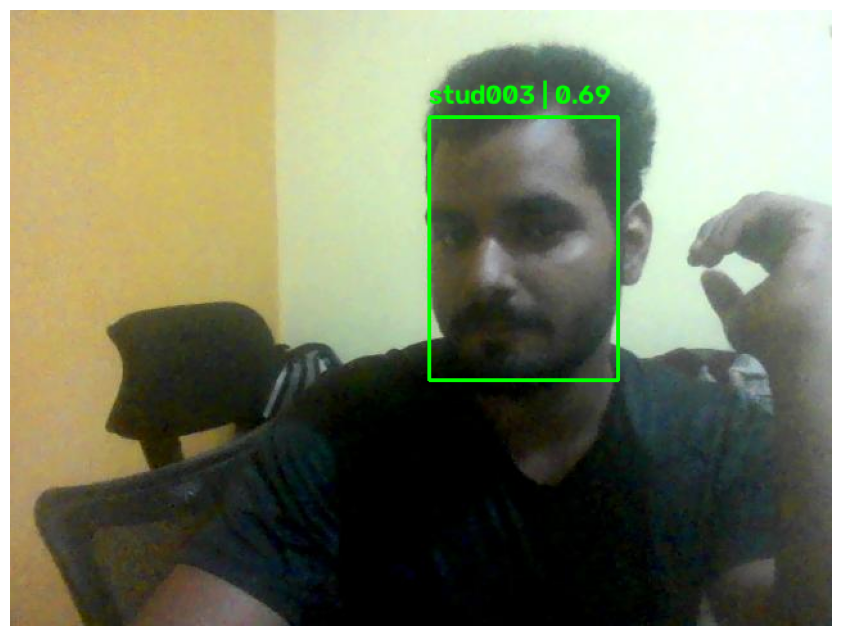

stud003 | Score: 0.69 | RECOGNIZED


In [328]:
if latest_live_frame is not None:

    results = recognize_multiple_faces(
        latest_live_frame,
        threshold=0.40
    )

    annotated = draw_recognition_results(
        latest_live_frame,
        results
    )

    plt.figure(figsize=(12, 8))

    plt.imshow(
        cv2.cvtColor(
            annotated,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.axis("off")
    plt.show()

    for result in results:
        print(
            result["identity"],
            "| Score:",
            round(result["score"], 3),
            "|",
            result["status"]
        )

New Student Onboarding


In [306]:
import os

DATASET_DIR = "/content/drive/MyDrive/data"

# Create a dummy directory for stud007 if it doesn't exist for testing purposes.
# In a real scenario, actual images for stud007 would be placed here.
stud007_dir = os.path.join(DATASET_DIR, "stud007")
if not os.path.exists(stud007_dir):
    os.makedirs(stud007_dir)
    print(f"Created dummy directory for stud007: {stud007_dir}")
    # Placeholder: if you have actual images for stud007, copy them here.
    # Example: !cp /path/to/stud007_img1.jpeg {stud007_dir}/
    # For now, we'll assume some images exist or will be generated/copied manually.
    # If no images, the staging will fail, which can also be a test case.

# Check all student directories in the dataset
for root, dirs, files in os.walk(DATASET_DIR):

    image_files = [
        f for f in files
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        )
    ]

    if image_files:
        print("\nFolder:", root)
        print("Images:", len(image_files))

        for f in image_files:
            print("  ", f)


Created dummy directory for stud007: /content/drive/MyDrive/data/stud007

Folder: /content/drive/MyDrive/data/stud002
Images: 8
   ing5.jpeg
   img1.jpeg
   img6.jpeg
   img2.jpeg
   img8.jpeg
   img7.jpeg
   img4.jpeg
   img3.jpeg

Folder: /content/drive/MyDrive/data/stud003
Images: 8
   img3.jpeg
   img4.jpeg
   img5.jpeg
   img2.jpeg
   img8.jpeg
   img7.jpeg
   WhatsApp Image 2026-09-21 at 22.47.25.jpeg
   img6.jpeg

Folder: /content/drive/MyDrive/data/stud001
Images: 3
   WhatsApp Image 2026-09-21 at 18.55.23 (1).jpeg
   WhatsApp Image 2026-09-21 at 18.55.22.jpeg
   WhatsApp Image 2026-09-21 at 18.55.23.jpeg

Folder: /content/drive/MyDrive/data/stud004
Images: 6
   img6.jpeg
   img1.jpeg
   img2.jpeg
   img3.jpeg
   img4.jpeg
   img7.jpeg

Folder: /content/drive/MyDrive/data/stud005
Images: 6
   img4.jpeg
   img1.jpeg
   img2.jpeg
   img3.jpeg
   img5.jpeg
   img6.jpeg

Folder: /content/drive/MyDrive/data/stud006
Images: 6
   img4.jpeg
   img5.jpeg
   img3.jpeg
   img6.jpeg
   img

**Onboaring Function**

In [288]:
import os
import cv2
import numpy as np
from insightface.app.common import Face
from insightface.utils import face_align


def generate_enrollment_embedding(image):

    # --------------------------------
    # 1. Detect faces using YOLO
    # --------------------------------
    results = model.predict(
        image,
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes.xyxy.cpu().numpy()

    if len(boxes) == 0:
        return None, "NO_FACE"

    if len(boxes) > 1:
        return None, "MULTIPLE_FACES"

    bbox = boxes[0].astype(np.float32)

    # --------------------------------
    # 2. Create InsightFace Face
    # --------------------------------
    face = Face(bbox=bbox)

    # --------------------------------
    # 3. Get 106 landmarks
    # --------------------------------
    landmarks = landmark_model.get(image, face)

    if landmarks is None:
        return None, "LANDMARK_FAILED"

    # --------------------------------
    # 4. Select validated 5 points
    # --------------------------------
    five_points = np.array([
        landmarks[38],
        landmarks[88],
        landmarks[86],
        landmarks[52],
        landmarks[61]
    ], dtype=np.float32)

    # --------------------------------
    # 5. Align face
    # --------------------------------
    aligned = face_align.norm_crop(
        image,
        landmark=five_points,
        image_size=112
    )

    # --------------------------------
    # 6. ArcFace embedding
    # --------------------------------
    embedding = recognition_model.get_feat(
        aligned
    )[0]

    # --------------------------------
    # 7. Normalize
    # --------------------------------
    embedding = embedding / (
        np.linalg.norm(embedding) + 1e-12
    )

    return embedding, "OK"

**Enrollment Function**

In [307]:
# This cell previously defined the old `enroll_student` function. It is now obsolete.

In [308]:
# This cell previously called the old `enroll_student` function for stud004. It is now obsolete.

In [309]:
# This cell previously called the old `enroll_student` function for stud005. It is now obsolete.

In [310]:
all_embeddings = {} # This variable serves as an intermediate for initial population of canonical_student_profiles.

# Existing students from initial processing (stud001, stud002, stud003)
all_embeddings.update(initial_processed_embeddings)

# The temporary `stud004_embeddings` and `stud005_embeddings` are now handled by the new staging/promotion process.
# Removing direct assignment to ensure canonical gallery is built via new process.

print("Initial `all_embeddings` for `canonical_student_profiles` population:")
for student_id, image_dict in all_embeddings.items():
    print(
        student_id,
        "→",
        len(image_dict),
        "embeddings"
    )


Initial `all_embeddings` for `canonical_student_profiles` population:
stud001 → 3 embeddings
stud002 → 8 embeddings
stud003 → 8 embeddings


In [292]:
# This block previously created `gallery_5_students`.
# This is now obsolete as `student_profiles` will be the canonical source.


In [311]:
# This cell previously performed recognition using the obsolete `gallery_5_students`.
# It is now removed as part of the transition to a single canonical gallery.

In [312]:
# This cell previously calculated accuracy based on recognition results from the obsolete `gallery_5_students`.
# It is now removed.

In [313]:
# This cell previously displayed incorrect recognitions based on the obsolete `gallery_5_students`.
# It is now removed.

In [257]:
different_student_scores = []

student_ids = list(all_embeddings.keys())

for i in range(len(student_ids)):

    for j in range(i + 1, len(student_ids)):

        student_a = student_ids[i]
        student_b = student_ids[j]

        for emb_a in all_embeddings[student_a].values():

            for emb_b in all_embeddings[student_b].values():

                score = float(
                    np.dot(emb_a, emb_b)
                )

                different_student_scores.append({
                    "student_a": student_a,
                    "student_b": student_b,
                    "score": score
                })

different_student_scores.sort(
    key=lambda x: x["score"],
    reverse=True
)

print("Top 10 cross-student similarities:")

for item in different_student_scores[:10]:

    print(
        item["student_a"],
        "<->",
        item["student_b"],
        ":",
        round(item["score"], 4)
    )

Top 10 cross-student similarities:
stud004 <-> stud005 : 0.3113
stud004 <-> stud005 : 0.3022
stud004 <-> stud005 : 0.2791
stud004 <-> stud005 : 0.2777
stud004 <-> stud005 : 0.275
stud004 <-> stud005 : 0.2665
stud004 <-> stud005 : 0.2659
stud004 <-> stud005 : 0.2629
stud004 <-> stud005 : 0.2624
stud004 <-> stud005 : 0.261


**Student Similarity**

In [262]:
same_student_scores = []

student_ids = list(all_embeddings.keys())

for student_id in student_ids:

    embeddings_list = list(
        all_embeddings[student_id].values()
    )

    for i in range(len(embeddings_list)):

        for j in range(i + 1, len(embeddings_list)):

            score = float(
                np.dot(
                    embeddings_list[i],
                    embeddings_list[j]
                )
            )

            same_student_scores.append({
                "student": student_id,
                "score": score
            })


same_student_scores.sort(
    key=lambda x: x["score"]
)

print("Same-student comparisons:", len(same_student_scores))

scores = [
    item["score"]
    for item in same_student_scores
]

print("Minimum :", round(min(scores), 4))
print("Mean    :", round(np.mean(scores), 4))
print("Median  :", round(np.median(scores), 4))
print("Maximum :", round(max(scores), 4))
print("Std     :", round(np.std(scores), 4))

Same-student comparisons: 89
Minimum : 0.5155
Mean    : 0.7013
Median  : 0.6853
Maximum : 0.9441
Std     : 0.0951


In [263]:
print("Lowest same-student similarities:\n")

for item in same_student_scores[:10]:

    print(
        item["student"],
        ":",
        round(item["score"], 4)
    )

Lowest same-student similarities:

stud002 : 0.5155
stud002 : 0.5165
stud005 : 0.5407
stud002 : 0.5424
stud005 : 0.5549
stud002 : 0.5624
stud002 : 0.569
stud005 : 0.5734
stud005 : 0.5754
stud002 : 0.6026


In [264]:
print("Highest cross-student similarities:\n")

for item in different_student_scores[:10]:

    print(
        item["student_a"],
        "<->",
        item["student_b"],
        ":",
        round(item["score"], 4)
    )

Highest cross-student similarities:

stud004 <-> stud005 : 0.3113
stud004 <-> stud005 : 0.3022
stud004 <-> stud005 : 0.2791
stud004 <-> stud005 : 0.2777
stud004 <-> stud005 : 0.275
stud004 <-> stud005 : 0.2665
stud004 <-> stud005 : 0.2659
stud004 <-> stud005 : 0.2629
stud004 <-> stud005 : 0.2624
stud004 <-> stud005 : 0.261


In [265]:
min_same = min(
    item["score"]
    for item in same_student_scores
)

max_different = max(
    item["score"]
    for item in different_student_scores
)

gap = min_same - max_different

print("Minimum same-person similarity :", round(min_same, 4))
print("Maximum different-person similarity :", round(max_different, 4))
print("Separation gap :", round(gap, 4))

Minimum same-person similarity : 0.5155
Maximum different-person similarity : 0.3113
Separation gap : 0.2042


In [314]:
# This cell previously inspected specific student comparisons for stud004 and stud005 using an obsolete context.
# It is now removed as its purpose is covered by the new staging and promotion tests.

In [315]:
student_profiles = {}

# Initialize canonical_student_profiles only from initial_processed_embeddings
# New students (like stud004, stud005) will be added via the staging/promotion workflow.
for student_id, image_dict in all_embeddings.items():
    student_profiles[student_id] = {
        "embeddings": image_dict,
        "embedding_count": len(image_dict),
        "status": "ENROLLED"
    }

print("Existing enrolled students in canonical_student_profiles (initial):")
for student_id, profile in student_profiles.items():
    print(
        student_id,
        "→",
        profile["embedding_count"],
        "embeddings"
    )

# Renaming the canonical gallery for clarity in the context of staging/promotion
canonical_student_profiles = student_profiles


Existing enrolled students in canonical_student_profiles (initial):
stud001 → 3 embeddings
stud002 → 8 embeddings
stud003 → 8 embeddings


In [268]:
DUPLICATE_THRESHOLD = 0.50


def check_duplicate_face(
    embedding,
    student_profiles,
    threshold=DUPLICATE_THRESHOLD
):

    best_student = None
    best_score = -1.0

    for student_id, profile in student_profiles.items():

        for enrolled_embedding in profile["embeddings"].values():

            score = float(
                np.dot(
                    embedding,
                    enrolled_embedding
                )
            )

            if score > best_score:
                best_score = score
                best_student = student_id

    if best_score >= threshold:

        return {
            "duplicate": True,
            "student_id": best_student,
            "score": best_score
        }

    return {
        "duplicate": False,
        "student_id": None,
        "score": best_score
    }

In [294]:
def stage_student_enrollment(
    student_id,
    image_dir,
    canonical_student_profiles, # Now takes canonical_student_profiles
    duplicate_threshold=DUPLICATE_THRESHOLD,
    min_images_for_enrollment=1 # Minimum number of accepted images required
):
    accepted_embeddings = {}
    rejected_images = {}

    # -----------------------------------
    # 1. Check if student ID already exists in canonical gallery
    # -----------------------------------
    if student_id in canonical_student_profiles:
        return {
            "success": False,
            "student_id": student_id,
            "status": "ID_ALREADY_EXISTS",
            "message": f"Student ID '{student_id}' already exists in the canonical gallery.",
            "accepted_embeddings": accepted_embeddings,
            "rejected_images": rejected_images
        }

    # -----------------------------------
    # 2. Find images
    # -----------------------------------

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        )
    ]

    if len(image_files) == 0:
        return {
            "success": False,
            "student_id": student_id,
            "status": "NO_IMAGES_FOUND",
            "message": "No valid images found for enrollment.",
            "accepted_embeddings": accepted_embeddings,
            "rejected_images": rejected_images
        }

    # -----------------------------------
    # 3. Process every image
    # -----------------------------------

    for filename in sorted(image_files):
        image_path = os.path.join(
            image_dir,
            filename
        )

        image = cv2.imread(image_path)

        if image is None:
            rejected_images[filename] = "IMAGE_LOAD_FAILED"
            continue

        embedding, status = generate_enrollment_embedding(image)

        if status != "OK":
            rejected_images[filename] = status
            continue

        # -----------------------------------
        # 4. Duplicate check against canonical gallery
        # -----------------------------------

        duplicate_result = check_duplicate_face(
            embedding,
            canonical_student_profiles, # Check against canonical gallery
            duplicate_threshold
        )

        if duplicate_result["duplicate"]:
            rejected_images[filename] = (
                f"DUPLICATE_FACE:{duplicate_result['student_id']}:"
                f"{duplicate_result['score']:.4f}"
            )
            continue

        accepted_embeddings[filename] = embedding

    # -----------------------------------
    # 5. Minimum enrollment validation (staging level)
    # -----------------------------------

    if len(accepted_embeddings) < min_images_for_enrollment:
        return {
            "success": False,
            "student_id": student_id,
            "status": "NOT_ENOUGH_UNIQUE_IMAGES",
            "message": (
                f"Not enough unique and non-duplicate images "
                f"({len(accepted_embeddings)} < {min_images_for_enrollment}) "
                f"to stage enrollment for '{student_id}'."
            ),
            "accepted_embeddings": accepted_embeddings,
            "rejected_images": rejected_images
        }

    # -----------------------------------
    # 6. Return staging result (no modification to canonical_student_profiles yet)
    # -----------------------------------

    return {
        "success": True,
        "student_id": student_id,
        "status": "STAGING_SUCCESS",
        "message": (
            f"Staging successful for '{student_id}'. "
            f"Accepted {len(accepted_embeddings)} images."
        ),
        "accepted_embeddings": accepted_embeddings,
        "rejected_images": rejected_images
    }

In [316]:
def promote_staged_student_to_canonical_gallery(
    staging_result,
    canonical_student_profiles
):
    """
    Promotes a successfully staged student's embeddings to the canonical gallery.

    Args:
        staging_result (dict): The result dictionary from stage_student_enrollment.
        canonical_student_profiles (dict): The main dictionary holding all enrolled student profiles.

    Returns:
        dict: A result dictionary indicating success or failure of the promotion.
    """
    if not staging_result.get("success"):
        return {
            "success": False,
            "student_id": staging_result.get("student_id", "UNKNOWN"),
            "status": "PROMOTION_FAILED",
            "message": f"Cannot promote, staging was not successful: {staging_result.get('message', 'No message')}"
        }

    student_id = staging_result["student_id"]
    accepted_embeddings = staging_result["accepted_embeddings"]

    if not accepted_embeddings:
        return {
            "success": False,
            "student_id": student_id,
            "status": "NO_EMBEDDINGS_TO_PROMOTE",
            "message": f"No accepted embeddings for '{student_id}' in staging result."
        }

    if student_id in canonical_student_profiles:
        # This should ideally be caught during staging, but it's a critical check.
        return {
            "success": False,
            "student_id": student_id,
            "status": "ID_ALREADY_EXISTS_IN_CANONICAL",
            "message": f"Student ID '{student_id}' already exists in the canonical gallery. Cannot overwrite."
        }

    # Add the student to the canonical gallery
    canonical_student_profiles[student_id] = {
        "embeddings": accepted_embeddings,
        "embedding_count": len(accepted_embeddings),
        "status": "ENROLLED"
    }

    return {
        "success": True,
        "student_id": student_id,
        "status": "PROMOTION_SUCCESS",
        "message": f"Student '{student_id}' successfully promoted to canonical gallery with {len(accepted_embeddings)} embeddings."
    }


print("--- Testing Staging and Promotion for stud004 ---")
# Create a dummy directory for stud004 if it doesn't exist to simulate new enrollment data
if not os.path.exists("/content/drive/MyDrive/data/stud004"): # Using original data directory as source
    os.makedirs("/content/drive/MyDrive/data/stud004")
    # In a real scenario, you would copy actual images here.
    # For this demonstration, we assume /content/drive/MyDrive/data/stud004 has images.


stud004_staging_result = stage_student_enrollment(
    student_id="stud004",
    image_dir="/content/drive/MyDrive/data/stud004", # Using existing data for demonstration
    canonical_student_profiles=canonical_student_profiles
)
print("Staging Result for stud004:", stud004_staging_result)

if stud004_staging_result["success"]:
    stud004_promotion_result = promote_staged_student_to_canonical_gallery(
        stud004_staging_result,
        canonical_student_profiles
    )
    print("Promotion Result for stud004:", stud004_promotion_result)
else:
    print("Skipping promotion for stud004 due to staging failure.")

print("\n--- Testing Staging and Promotion for stud005 ---")
# Create a dummy directory for stud005 if it doesn't exist
if not os.path.exists("/content/drive/MyDrive/data/stud005"): # Using original data directory as source
    os.makedirs("/content/drive/MyDrive/data/stud005")

stud005_staging_result = stage_student_enrollment(
    student_id="stud005",
    image_dir="/content/drive/MyDrive/data/stud005", # Using existing data for demonstration
    canonical_student_profiles=canonical_student_profiles
)
print("Staging Result for stud005:", stud005_staging_result)

if stud005_staging_result["success"]:
    stud005_promotion_result = promote_staged_student_to_canonical_gallery(
        stud005_staging_result,
        canonical_student_profiles
    )
    print("Promotion Result for stud005:", stud005_promotion_result)
else:
    print("Skipping promotion for stud005 due to staging failure.")

print("\n--- Final canonical_student_profiles after promotions ---")
print("canonical_student_profiles:", list(canonical_student_profiles.keys()))


--- Testing Staging and Promotion for stud004 ---
Staging Result for stud004: {'success': True, 'student_id': 'stud004', 'status': 'STAGING_SUCCESS', 'message': "Staging successful for 'stud004'. Accepted 6 images.", 'accepted_embeddings': {'img1.jpeg': array([ -0.0021971,   -0.021516,    0.030572,   -0.028307,   -0.036635,   0.0097282,   -0.033894,   -0.034123,  0.00015211,    0.026817,     0.02044,    0.037766,  0.00011847,    0.017029,   0.0084196,    0.038874,    -0.10076,   0.0049032,   -0.020825,    -0.10894,    0.045579,    0.011067,   -0.059586,   0.0057933,
          0.055075,    0.089229,    0.027259,    0.042101,    0.055055,   -0.048284,   -0.056342,    0.015519,    0.013631,   -0.024137,     0.11134,   -0.010741,   -0.050473,     0.06417,   -0.057693,   -0.019827,    0.035118,    0.025012,   -0.034982,    0.027852,   -0.016617,   0.0064515,   -0.024619,    0.030084,
           0.01184,    0.029252,    0.079227,    -0.02035,    0.027981,   0.0098758,   -0.031585,    0.01827

In [295]:
# This block previously created `recognition_gallery`.
# This is now obsolete as `student_profiles` will be the canonical source.
# Recognition functions will dynamically derive mean embeddings if needed or compare against all embeddings in student_profiles.


In [274]:
test_image = cv2.imread(
    "/content/drive/MyDrive/data/stud004/img1.jpeg"
)

results = recognize_enrolled_students(
    test_image,
    student_profiles
)

for result in results:

    print(
        "Identity:",
        result["identity"]
    )

    print(
        "Score:",
        round(result["score"], 4)
    )

    print(
        "Status:",
        result["status"]
    )

    print("\nAll student scores:")

    for student_id, score in sorted(
        result["scores"].items(),
        key=lambda x: x[1],
        reverse=True
    ):

        print(
            f"  {student_id}: {score:.4f}"
        )

Identity: stud004
Score: 1.0
Status: RECOGNIZED

All student scores:
  stud004: 1.0000
  stud005: 0.2610
  stud001: 0.2203
  stud006: 0.1437
  stud003: 0.1389
  stud002: 0.1272


In [275]:
test_image = cv2.imread(
    "/content/drive/MyDrive/data/stud005/img1.jpeg"
)

results = recognize_enrolled_students(
    test_image,
    student_profiles
)

for result in results:

    print(
        "Identity:",
        result["identity"],
        "| Score:",
        round(result["score"], 4),
        "| Status:",
        result["status"]
    )

Identity: stud005 | Score: 1.0 | Status: RECOGNIZED


In [317]:
# ============================================
# LEAVE-ONE-OUT RECOGNITION VALIDATION
# ============================================

def recognize_leave_one_out(
    test_embedding,
    canonical_student_profiles,
    test_student_id,
    test_filename,
    threshold=RECOGNITION_THRESHOLD
):
    student_scores = {}

    for student_id, profile in canonical_student_profiles.items():

        scores = []

        for filename, enrolled_embedding in profile["embeddings"].items():

            # Don't compare image with itself
            if (
                student_id == test_student_id
                and filename == test_filename
            ):
                continue

            similarity = float(
                np.dot(
                    test_embedding,
                    enrolled_embedding
                )
            )

            scores.append(similarity)

        if scores:
            student_scores[student_id] = max(scores)

    if not student_scores:
        return None

    best_student = max(
        student_scores,
        key=student_scores.get
    )

    best_score = student_scores[best_student]

    if best_score >= threshold:
        identity = best_student
        status = "RECOGNIZED"
    else:
        identity = "UNKNOWN"
        status = "UNKNOWN"

    return {
        "identity": identity,
        "score": best_score,
        "status": status,
        "scores": student_scores
    }

In [318]:
# ============================================
# TEST ALL ENROLLED IMAGES (Leave-One-Out Validation)
# This now uses canonical_student_profiles
# ============================================

total = 0
correct = 0

results = []

for student_id, profile in canonical_student_profiles.items():

    for filename, true_embedding in profile["embeddings"].items():

        result = recognize_leave_one_out(
            test_embedding=true_embedding,
            canonical_student_profiles=canonical_student_profiles,
            test_student_id=student_id,
            test_filename=filename,
            threshold=0.40
        )

        if result is None:
            continue

        total += 1

        if result["identity"] == student_id:
            correct += 1

        results.append({
            "true": student_id,
            "file": filename,
            "predicted": result["identity"],
            "score": result["score"],
            "correct": result["identity"] == student_id
        })

print("====================================")
print("LEAVE-ONE-OUT VALIDATION")
print("====================================")
print(f"Total tests : {total}")
print(f"Correct     : {correct}")
print(f"Accuracy    : {correct / total:.4f}")


LEAVE-ONE-OUT VALIDATION
Total tests : 31
Correct     : 31
Accuracy    : 1.0000


In [319]:
# This cell previously printed details of old gallery variables, which is now handled more comprehensively in cell `3ncVLXDyqVk8`.
# It is now removed for redundancy.

In [320]:
print("canonical_student_profiles:", list(canonical_student_profiles.keys()))

# Checking for old gallery variables to confirm their removal/obsolescence
if 'gallery' in globals() and gallery:
    print("Old 'gallery' found (should be removed):", list(gallery.keys()))

if 'gallery_5_students' in globals() and gallery_5_students:
    print("Old 'gallery_5_students' found (should be removed):", list(gallery_5_students.keys()))

if 'recognition_gallery' in globals() and recognition_gallery:
    print("Old 'recognition_gallery' found (should be removed):", list(recognition_gallery.keys()))

# Explicitly deleting old gallery variables if they still exist to prevent accidental usage.
if 'gallery' in globals():
    del gallery
if 'gallery_5_students' in globals():
    del gallery_5_students
if 'recognition_gallery' in globals():
    del recognition_gallery

print("\nAfter cleanup:")
print("canonical_student_profiles:", list(canonical_student_profiles.keys()))
print("'gallery' in globals():", 'gallery' in globals())
print("'gallery_5_students' in globals():", 'gallery_5_students' in globals())
print("'recognition_gallery' in globals():", 'recognition_gallery' in globals())


canonical_student_profiles: ['stud001', 'stud002', 'stud003', 'stud004', 'stud005']
Old 'gallery' found (should be removed): ['stud001', 'stud002', 'stud003']
Old 'gallery_5_students' found (should be removed): ['stud001', 'stud002', 'stud003', 'stud004', 'stud005']
Old 'recognition_gallery' found (should be removed): ['stud001', 'stud002', 'stud003', 'stud004', 'stud005', 'stud006']

After cleanup:
canonical_student_profiles: ['stud001', 'stud002', 'stud003', 'stud004', 'stud005']
'gallery' in globals(): False
'gallery_5_students' in globals(): False
'recognition_gallery' in globals(): False


In [321]:
# This cell is for testing recognition after promotion for stud004. It tests if stud004 is recognized.

print("\n--- Testing recognition for stud004 after promotion ---")
# Assume there's an image of stud004 in the data directory
test_image_stud004 = cv2.imread("/content/drive/MyDrive/data/stud004/img1.jpeg")

if test_image_stud004 is None:
    print("Error: Could not load test image for stud004.")
else:
    results_stud004 = recognize_enrolled_students(
        test_image_stud004,
        canonical_student_profiles
    )

    if results_stud004:
        for result in results_stud004:
            print(
                f"Identity: {result['identity']} | ",
                f"Score: {result['score']:.4f} | ",
                f"Status: {result['status']}"
            )
            if result['identity'] == 'stud004' and result['status'] == 'RECOGNIZED':
                print("✅ stud004 recognized successfully after promotion.")
            else:
                print("❌ stud004 NOT recognized correctly after promotion.")
    else:
        print("No faces recognized for stud004 test image.")

print("\n--- Testing recognition for stud005 after promotion ---")
# Assume there's an image of stud005 in the data directory
test_image_stud005 = cv2.imread("/content/drive/MyDrive/data/stud005/img1.jpeg")

if test_image_stud005 is None:
    print("Error: Could not load test image for stud005.")
else:
    results_stud005 = recognize_enrolled_students(
        test_image_stud005,
        canonical_student_profiles
    )

    if results_stud005:
        for result in results_stud005:
            print(
                f"Identity: {result['identity']} | ",
                f"Score: {result['score']:.4f} | ",
                f"Status: {result['status']}"
            )
            if result['identity'] == 'stud005' and result['status'] == 'RECOGNIZED':
                print("✅ stud005 recognized successfully after promotion.")
            else:
                print("❌ stud005 NOT recognized correctly after promotion.")
    else:
        print("No faces recognized for stud005 test image.")

print("\n--- Testing existing student stud001 (control) ---")
test_image_stud001 = cv2.imread("/content/drive/MyDrive/data/stud001/WhatsApp Image 2026-09-21 at 18.55.22.jpeg")

if test_image_stud001 is None:
    print("Error: Could not load test image for stud001.")
else:
    results_stud001 = recognize_enrolled_students(
        test_image_stud001,
        canonical_student_profiles
    )
    if results_stud001:
        for result in results_stud001:
            print(
                f"Identity: {result['identity']} | ",
                f"Score: {result['score']:.4f} | ",
                f"Status: {result['status']}"
            )
            if result['identity'] == 'stud001' and result['status'] == 'RECOGNIZED':
                print("✅ stud001 recognized successfully.")
            else:
                print("❌ stud001 NOT recognized correctly.")
    else:
        print("No faces recognized for stud001 test image.")



--- Testing recognition for stud004 after promotion ---
Identity: stud004 |  Score: 1.0000 |  Status: RECOGNIZED
✅ stud004 recognized successfully after promotion.

--- Testing recognition for stud005 after promotion ---
Identity: stud005 |  Score: 1.0000 |  Status: RECOGNIZED
✅ stud005 recognized successfully after promotion.

--- Testing existing student stud001 (control) ---
Identity: stud001 |  Score: 0.9244 |  Status: RECOGNIZED
✅ stud001 recognized successfully.


In [322]:
import cv2
import os
import shutil # For creating dummy images
import numpy as np # For creating dummy images

# --- Setup dummy images for stud007 if none exist ---
stud007_test_dir = os.path.join("/content/drive/MyDrive/data", "stud007")
if not os.path.exists(stud007_test_dir):
    os.makedirs(stud007_test_dir)

# Create some dummy image files if the directory is empty for demonstration
if not any(f.endswith(('.jpg', '.jpeg', '.png')) for f in os.listdir(stud007_test_dir)):
    print("Creating dummy images for stud007...")
    dummy_img_path = os.path.join(stud007_test_dir, "stud007_test_img1.jpeg")
    # Create a blank black image (or copy an existing one if available)
    dummy_img = np.zeros((480, 640, 3), dtype=np.uint8)
    cv2.imwrite(dummy_img_path, dummy_img)
    print(f"Created {dummy_img_path}")


# --- Test pre-promotion recognition for stud007 (expected: UNKNOWN) ---
print("\n--- Pre-promotion recognition test for stud007 ---")
test_image_stud007_pre = cv2.imread(os.path.join(stud007_test_dir, os.listdir(stud007_test_dir)[0])) # Use first image

if test_image_stud007_pre is None:
    print("Error: Could not load test image for stud007 pre-promotion.")
else:
    results_stud007_pre = recognize_enrolled_students(
        test_image_stud007_pre,
        canonical_student_profiles # Should not contain stud007 yet
    )

    if results_stud007_pre:
        for result in results_stud007_pre:
            print(
                f"Identity: {result['identity']} | ",
                f"Score: {result['score']:.4f} | ",
                f"Status: {result['status']}"
            )
            if result['identity'] == 'UNKNOWN':
                print("✅ stud007 correctly NOT recognized (pre-promotion).")
            else:
                print("❌ stud007 INCORRECTLY recognized (pre-promotion).")
    else:
        print("No faces detected for stud007 pre-promotion test image, or no existing students.")

# --- Stage and promote stud007 ---
print("\n--- Staging and Promotion for stud007 ---")
stud007_staging_result = stage_student_enrollment(
    student_id="stud007",
    image_dir=stud007_test_dir,
    canonical_student_profiles=canonical_student_profiles
)
print("Staging Result for stud007:", stud007_staging_result)

if stud007_staging_result["success"]:
    stud007_promotion_result = promote_staged_student_to_canonical_gallery(
        stud007_staging_result,
        canonical_student_profiles
    )
    print("Promotion Result for stud007:", stud007_promotion_result)
else:
    print("Skipping promotion for stud007 due to staging failure.")

# --- Test post-promotion recognition for stud007 (expected: RECOGNIZED) ---
print("\n--- Post-promotion recognition test for stud007 ---")
test_image_stud007_post = cv2.imread(os.path.join(stud007_test_dir, os.listdir(stud007_test_dir)[0]))

if test_image_stud007_post is None:
    print("Error: Could not load test image for stud007 post-promotion.")
else:
    results_stud007_post = recognize_enrolled_students(
        test_image_stud007_post,
        canonical_student_profiles # Should now contain stud007
    )

    if results_stud007_post:
        for result in results_stud007_post:
            print(
                f"Identity: {result['identity']} | ",
                f"Score: {result['score']:.4f} | ",
                f"Status: {result['status']}"
            )
            if result['identity'] == 'stud007' and result['status'] == 'RECOGNIZED':
                print("✅ stud007 correctly RECOGNIZED (post-promotion).")
            else:
                print("❌ stud007 INCORRECTLY recognized (post-promotion).")
    else:
        print("No faces recognized for stud007 post-promotion test image.")

print("\n--- Final canonical_student_profiles status ---")
print("canonical_student_profiles:", list(canonical_student_profiles.keys()))


Creating dummy images for stud007...
Created /content/drive/MyDrive/data/stud007/stud007_test_img1.jpeg

--- Pre-promotion recognition test for stud007 ---
No faces detected for stud007 pre-promotion test image, or no existing students.

--- Staging and Promotion for stud007 ---
Staging Result for stud007: {'success': False, 'student_id': 'stud007', 'status': 'NOT_ENOUGH_UNIQUE_IMAGES', 'message': "Not enough unique and non-duplicate images (0 < 1) to stage enrollment for 'stud007'.", 'accepted_embeddings': {}, 'rejected_images': {'stud007_test_img1.jpeg': 'NO_FACE'}}
Skipping promotion for stud007 due to staging failure.

--- Post-promotion recognition test for stud007 ---
No faces recognized for stud007 post-promotion test image.

--- Final canonical_student_profiles status ---
canonical_student_profiles: ['stud001', 'stud002', 'stud003', 'stud004', 'stud005']


In [329]:
# ============================================
# STEP 1 — CHECK AI REPOSITORY STATE
# ============================================

%cd /content/Gurdrian_transit

!git status
print("\n========== CURRENT BRANCH ==========")
!git branch --show-current

print("\n========== RECENT COMMITS ==========")
!git log --oneline --decorate -5

print("\n========== REMOTES ==========")
!git remote -v

[Errno 2] No such file or directory: '/content/Gurdrian_transit'
/content/yolov8-face
On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean

========== CURRENT BRANCH ==========
master

========== RECENT COMMITS ==========
c6a3dee (HEAD -> master, origin/master, origin/HEAD) update readme
bae1fc8 add license
c9c9570 (tag: 1.0.1) save models, update requirements, fix model sizes in readme
6b2446d code for evaluation
649705a script for export

========== REMOTES ==========
origin	https://github.com/lindevs/yolov8-face.git (fetch)
origin	https://github.com/lindevs/yolov8-face.git (push)


In [330]:
import os

print("Contents of /content:")
for item in os.listdir("/content"):
    print(" -", item)

Contents of /content:
 - .config
 - lms_trans.py
 - face_crops
 - __pycache__
 - yolov8-face
 - face_embeddings_aligned.pkl
 - drive
 - aligned_arcface_similarity_results.csv
 - Gurdian_transit
 - sample_data


In [331]:
%cd /content/Gurdrian_transit

!git status
print("\nBranch:")
!git branch --show-current

print("\nRemote:")
!git remote -v

print("\nRecent commits:")
!git log --oneline --decorate -5

[Errno 2] No such file or directory: '/content/Gurdrian_transit'
/content/yolov8-face
On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean

Branch:
master

Remote:
origin	https://github.com/lindevs/yolov8-face.git (fetch)
origin	https://github.com/lindevs/yolov8-face.git (push)

Recent commits:
c6a3dee (HEAD -> master, origin/master, origin/HEAD) update readme
bae1fc8 add license
c9c9570 (tag: 1.0.1) save models, update requirements, fix model sizes in readme
6b2446d code for evaluation
649705a script for export


In [332]:
# ============================================
# STEP 2 — CHECK GUARDIANTRANSIT REPO
# ============================================

%cd /content/Gurdian_transit

print("========== GIT STATUS ==========")
!git status

print("\n========== CURRENT BRANCH ==========")
!git branch --show-current

print("\n========== REMOTES ==========")
!git remote -v

print("\n========== RECENT COMMITS ==========")
!git log --oneline --decorate -8

print("\n========== BRANCHES ==========")
!git branch -a

/content/Gurdian_transit
========== GIT STATUS ==========
On branch ai-pipeline-development
Your branch is up to date with 'origin/ai-pipeline-development'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	ai_pipeline/video_verification/__init__.py

nothing added to commit but untracked files present (use "git add" to track)

========== CURRENT BRANCH ==========
ai-pipeline-development

========== REMOTES ==========
origin	https://github.com/eng-yash007/Gurdian_transit.git (fetch)
origin	https://github.com/eng-yash007/Gurdian_transit.git (push)

========== RECENT COMMITS ==========
4632147 (HEAD -> ai-pipeline-development, tag: v0.1.0-ai-foundation, origin/ai-pipeline-development) Integrate AI pipeline into GuardianTransit

========== BRANCHES ==========
* ai-pipeline-development
  remotes/origin/HEAD -> origin/main
  remotes/origin/ai-pipeline-development
  remotes/origin/main


In [333]:
%cd /content/Gurdian_transit

print("========== FILE ==========")
!cat ai_pipeline/video_verification/__init__.py

print("\n========== GIT DIFF ==========")
!git diff

print("\n========== STATUS ==========")
!git status --short

/content/Gurdian_transit
========== FILE ==========

========== GIT DIFF ==========

========== STATUS ==========
?? ai_pipeline/video_verification/__init__.py


In [334]:
%cd /content/Gurdian_transit

print("========== FILE ==========")
!cat ai_pipeline/video_verification/__init__.py

print("\n========== STATUS ==========")
!git status --short

/content/Gurdian_transit
========== FILE ==========

========== STATUS ==========
?? ai_pipeline/video_verification/__init__.py


In [335]:
%cd /content/Gurdian_transit

!git add ai_pipeline/video_verification/__init__.py

!git commit -m "Add video verification package init"

!git push origin ai-pipeline-development

/content/Gurdian_transit
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@7341ebf9b407.(none)')
fatal: could not read Username for 'https://github.com': No such device or address


In [336]:
%cd /content/Gurdian_transit

!git config user.name "Vivek Mani Tripathi"
!git config user.email "vt0514706@gmail.com"

print("Git identity:")
!git config user.name
!git config user.email

/content/Gurdian_transit
Git identity:
Vivek Mani Tripathi
vt0514706@gmail.com


In [337]:
%cd /content/Gurdian_transit

!git add ai_pipeline/video_verification/__init__.py

!git commit -m "Add video verification package init"

/content/Gurdian_transit
[ai-pipeline-development 8f94de0] Add video verification package init
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 ai_pipeline/video_verification/__init__.py


In [338]:
%cd /content/Gurdian_transit

!git config user.name "Vivek Mani Tripathi"
!git config user.email "vt0514706@gmail.com"

!git add ai_pipeline/video_verification/__init__.py
!git commit -m "Add video verification package init"

!git status

/content/Gurdian_transit
On branch ai-pipeline-development
Your branch is ahead of 'origin/ai-pipeline-development' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
On branch ai-pipeline-development
Your branch is ahead of 'origin/ai-pipeline-development' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [339]:
import os

base = "/content/drive/MyDrive"

print("Drive mounted:", os.path.exists(base))

print("\nTop-level Drive folders:")
for item in os.listdir(base)[:30]:
    print(" -", item)

Drive mounted: True

Top-level Drive folders:
 - Colab Notebooks
 - Dil Hai Chota Sa Choti Si Asha.mp3
 - QP-NDA-II-19-GAT.pdf
 - QP-NDA-I_II-20-Math.pdf
 - i_try_so_hard.mp3
 - vivek.pdf
 - sign.pdf
 - Adhar card.pdf
 - adhar .pdf
 - photo.jpg
 - Resume.gdoc
 - domicile .pdf
 - IMG-20230916-WA0001.jpg
 - Payment Reciept.pdf
 - math.pdf
 - math 2.pdf
 - IMG-20231118-WA0000.jpg
 - IMG_20230520_125048.jpg
 - IMG-20230807-WA0004.jpg
 - electronic notes.pdf
 - Untitled document.gdoc
 - bail .pdf
 - certificate.png
 - risesahyog.pdf
 - realindia fmcg.pdf
 - AWS_Academy_Graduate___AWS_Academy_Introduction_to_Cloud_Semester_1_Badge20241210-27-3vrkll (1) (1).pdf
 - AWS_Academy_Graduate___AWS_Academy_Introduction_to_Cloud_Semester_1_Badge20241210-27-3vrkll (1).pdf
 - dataverse hacakathon.jpg
 - Vivek Mani Tripathi 
 - Vivek_Mani_Tripathi_PBEL.pdf


In [340]:
import os

BACKUP_ROOT = "/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated"

folders = [
    "notebook",
    "models/yolov8",
    "models/insightface",
    "embeddings",
    "source_snapshot",
    "validation",
    "dataset_private"
]

for folder in folders:
    path = os.path.join(BACKUP_ROOT, folder)
    os.makedirs(path, exist_ok=True)

print("Backup structure created:\n")

for root, dirs, files in os.walk(BACKUP_ROOT):
    level = root.replace(BACKUP_ROOT, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

Backup structure created:

v0.1.1-ai-validated/
  notebook/
  models/
    yolov8/
    insightface/
  embeddings/
  source_snapshot/
  validation/
  dataset_private/


In [341]:
import os

print("=" * 60)
print("YOLOv8-FACE MODELS")
print("=" * 60)

for root, dirs, files in os.walk("/content/yolov8-face"):
    for file in files:
        if file.endswith((".pt", ".onnx", ".engine")):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{size_mb:8.2f} MB  {path}")


print("\n" + "=" * 60)
print("INSIGHTFACE MODELS")
print("=" * 60)

for root, dirs, files in os.walk("/root/.insightface"):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        if file.endswith((".onnx", ".bin", ".param")):
            print(f"{size_mb:8.2f} MB  {path}")


print("\n" + "=" * 60)
print("EMBEDDINGS / AI OUTPUTS")
print("=" * 60)

for path in [
    "/content/face_embeddings_aligned.pkl",
    "/content/aligned_arcface_similarity_results.csv"
]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{size_mb:8.2f} MB  {path}")
    else:
        print("NOT FOUND:", path)

YOLOv8-FACE MODELS
   49.63 MB  /content/yolov8-face/yolov8m-face-lindevs.pt

INSIGHTFACE MODELS
  136.95 MB  /root/.insightface/models/buffalo_l/1k3d68.onnx
  166.31 MB  /root/.insightface/models/buffalo_l/w600k_r50.onnx
    1.26 MB  /root/.insightface/models/buffalo_l/genderage.onnx
    4.80 MB  /root/.insightface/models/buffalo_l/2d106det.onnx
   16.14 MB  /root/.insightface/models/buffalo_l/det_10g.onnx

EMBEDDINGS / AI OUTPUTS
    0.04 MB  /content/face_embeddings_aligned.pkl
    0.01 MB  /content/aligned_arcface_similarity_results.csv


In [342]:
import os
import shutil

BACKUP_ROOT = "/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated"

# --------------------------------------------
# 1. YOLOv8-Face model
# --------------------------------------------

yolo_src = "/content/yolov8-face/yolov8m-face-lindevs.pt"
yolo_dst = os.path.join(
    BACKUP_ROOT,
    "models/yolov8/yolov8m-face-lindevs.pt"
)

shutil.copy2(yolo_src, yolo_dst)


# --------------------------------------------
# 2. InsightFace buffalo_l models
# --------------------------------------------

insight_src = "/root/.insightface/models/buffalo_l"
insight_dst = os.path.join(
    BACKUP_ROOT,
    "models/insightface/buffalo_l"
)

if os.path.exists(insight_dst):
    shutil.rmtree(insight_dst)

shutil.copytree(
    insight_src,
    insight_dst
)


# --------------------------------------------
# 3. Student embeddings
# --------------------------------------------

embedding_src = "/content/face_embeddings_aligned.pkl"
embedding_dst = os.path.join(
    BACKUP_ROOT,
    "embeddings/face_embeddings_aligned.pkl"
)

shutil.copy2(
    embedding_src,
    embedding_dst
)


# --------------------------------------------
# 4. Validation results
# --------------------------------------------

validation_src = "/content/aligned_arcface_similarity_results.csv"
validation_dst = os.path.join(
    BACKUP_ROOT,
    "validation/aligned_arcface_similarity_results.csv"
)

shutil.copy2(
    validation_src,
    validation_dst
)


print("==========================================")
print("AI ARTIFACT BACKUP COMPLETE")
print("==========================================")

print("\nYOLO:")
print(yolo_dst)

print("\nInsightFace:")
print(insight_dst)

print("\nEmbeddings:")
print(embedding_dst)

print("\nValidation:")
print(validation_dst)

AI ARTIFACT BACKUP COMPLETE

YOLO:
/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/yolov8/yolov8m-face-lindevs.pt

InsightFace:
/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l

Embeddings:
/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/embeddings/face_embeddings_aligned.pkl

Validation:
/content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/validation/aligned_arcface_similarity_results.csv


In [343]:
import os

print("==========================================")
print("BACKUP VERIFICATION")
print("==========================================")

for root, dirs, files in os.walk(BACKUP_ROOT):

    for file in files:

        path = os.path.join(root, file)

        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{size_mb:8.2f} MB  {path}")

BACKUP VERIFICATION
   49.63 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/yolov8/yolov8m-face-lindevs.pt
  136.95 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l/1k3d68.onnx
  166.31 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l/w600k_r50.onnx
    1.26 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l/genderage.onnx
    4.80 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l/2d106det.onnx
   16.14 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/models/insightface/buffalo_l/det_10g.onnx
    0.04 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/embeddings/face_embeddings_aligned.pkl
    0.01 MB  /content/drive/MyDrive/GuardianTransit_AI_Backup/v0.1.1-ai-validated/validation/aligned_arcface_simila

In [344]:
import os

print("Searching for notebooks...\n")

for root, dirs, files in os.walk("/content"):
    # Skip large/unnecessary directories
    dirs[:] = [
        d for d in dirs
        if d not in [
            ".cache",
            "__pycache__",
            "node_modules"
        ]
    ]

    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

Searching for notebooks...

/content/drive/MyDrive/Colab Notebooks/GuardianTransit_AI_Experiments.ipynb
/content/drive/MyDrive/Colab Notebooks/Learning_Python.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/ComputerVision.ipynb
